# [GSE201578](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE201578)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-12-04
> - Modified: 2025-01-03

# 1. Experimental Design

> RNA-seq and ATAC-seq in MEF and mESC sequenced on different instrument models.
> - Naval-Sanchez M, Deshpande N, Tran M, Zhang J, Alhomrani M, Alsanie W, Nguyen Q and Nefzger CM (2022) Benchmarking of ATAC Sequencing Data From BGI’s Low-Cost DNBSEQ-G400 Instrument for Identification of Open and Occupied Chromatin Regions. Front. Mol. Biosci. 9:900323. doi: 10.3389/fmolb.2022.900323.
> - Omni-ATACseq
> - Illumina HiSeq X Ten, PE150
> - BGI DNBSEQ-G400, PE100

| Sample | Cell | Source | Strain | Genotype | FACS | Replicate | Instrument | Layout |
| - | - | - | - | - | - | - | - | - |
| mEF | EF | Embryonic fibroblasts | C57/Bl6 | Wild Type | THY1+ | rep1~3 | Illumina HiSeq X Ten | PE150 |
| mEF | EF | Embryonic fibroblasts | C57/Bl6 | Wild Type | THY1+ | rep1~3 | BGI DNBSEQ-G400 | PE100 |
| mESC | ESC | Embryonic stem cells | C57/Bl6 | Wild Type | THY1-/SSEA1+/EPCAM+ | rep1~3 | Illumina HiSeq X Ten | PE150 |
| mESC | ESC | Embryonic stem cells | C57/Bl6 | Wild Type | THY1-/SSEA1+/EPCAM+ | rep1~3 | BGI DNBSEQ-G400 | PE100 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/atacseq_Mm_mESC_DNBseq_GSE201578/02_output"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

# 2. Evaluate Library Quality

## 1). Mapping Statistics

| Sample | Total Fragments | Mapping Fragments | Mapping Rate | Unique Mapping Fragments | Unique Mapping Rate | PCR Duplicates Rate | Number Of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - |
| mESC_HiSeq_rep1 | 48718046 | 46971610 | 96.42% | 37778327 | 77.54% | 32.18% | 99321 | 47.70% |
| mESC_HiSeq_rep2 | 51929432 | 50012902 | 96.31% | 39140242 | 75.37% | 43.05% | 96775 | 48.99% |
| mESC_HiSeq_rep3 | 61552533 | 59359835 | 96.44% | 44650978 | 72.54% | 47.73% | 98875 | 47.80% |
| mESC_DNBSEQ_rep1 | 58847043 | 57027378 | 96.91% | 44614526 | 75.81% | 32.60% | 129122 | 46.91% |
| mESC_DNBSEQ_rep2 | 52386875 | 50700325 | 96.78% | 38522851 | 73.54% | 42.94% | 111041 | 46.87% |
| mESC_DNBSEQ_rep3 | 81893491 | 79440172 | 97.00% | 57467219 | 70.17% | 51.79% | 118725 | 46.22% |
| mEF_HiSeq_rep1 | 54834351 | 51893720 | 94.64% | 46105806 | 84.08% | 24.39% | 95765 | 45.29% |
| mEF_HiSeq_rep2 | 52871621 | 51415737 | 97.25% | 44958460 | 85.03% | 24.33% | 92756 | 44.21% |
| mEF_HiSeq_rep3 | 53569191 | 52071478 | 97.20% | 46021545 | 85.91% | 27.06% | 92423 | 47.95% |
| mEF_DNBSEQ_rep1 | 56043293 | 52887991 | 94.37% | 46685962 | 83.30% | 19.92% | 113491 | 43.16% |
| mEF_DNBSEQ_rep2 | 45628099 | 44190591 | 96.85% | 38056963 | 83.41% | 18.60% | 109406 | 41.50% |
| mEF_DNBSEQ_rep3 | 55883860 | 54311331 | 97.19% | 47256045 | 84.56% | 25.90% | 111238 | 45.51% |

## 2). Fragment Size Distribution

In [3]:
fragment_size <- file.path(data_dir, "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    separate(
        Sample, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell, levels = c("mESC", "mEF")), 
        Platform = factor(Platform, levels = c("HiSeq", "DNBSEQ")),
        Group = forcats::fct_cross(Cell, Platform, sep = "_"),
        Replicate = factor(Replicate)) |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

head(fragment_size)

Size,Occurrences,Sample,Cell,Platform,Replicate,Group,Freq
<int>,<int>,<chr>,<fct>,<fct>,<fct>,<fct>,<dbl>
36,83,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.001891479
37,122,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.002780247
38,146,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.003327180
39,181,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.004124792
40,270,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.006153005
41,413,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,mEF_DNBSEQ,0.009411818


In [4]:
fragment_size_summary <- fragment_size |>
    group_by(Sample) |>
    summarise(
        mean = matrixStats::weightedMean(
            Size, w = Occurrences, na.rm = TRUE),
        mean_trim_1pct = {
            q_low <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.01, na.rm = TRUE)
            q_high <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.99, na.rm = TRUE)
            idx <- Size >= q_low & Size <= q_high
            matrixStats::weightedMean(
                Size[idx], w = Occurrences[idx], na.rm = TRUE)},
        median = matrixStats::weightedMedian(
            Size, w = Occurrences, na.rm = TRUE)
    )

message(
    "Mean of fragment size: ", round(mean(
        fragment_size_summary$mean), 0),
    " (1% trimmed: ", round(mean(
        fragment_size_summary$mean_trim_1pct), 0), ")")
message(
    "Median of fragment size: ", round(mean(
        fragment_size_summary$median), 0))

Mean of fragment size: 174 (1% trimmed: 171)

Median of fragment size: 165



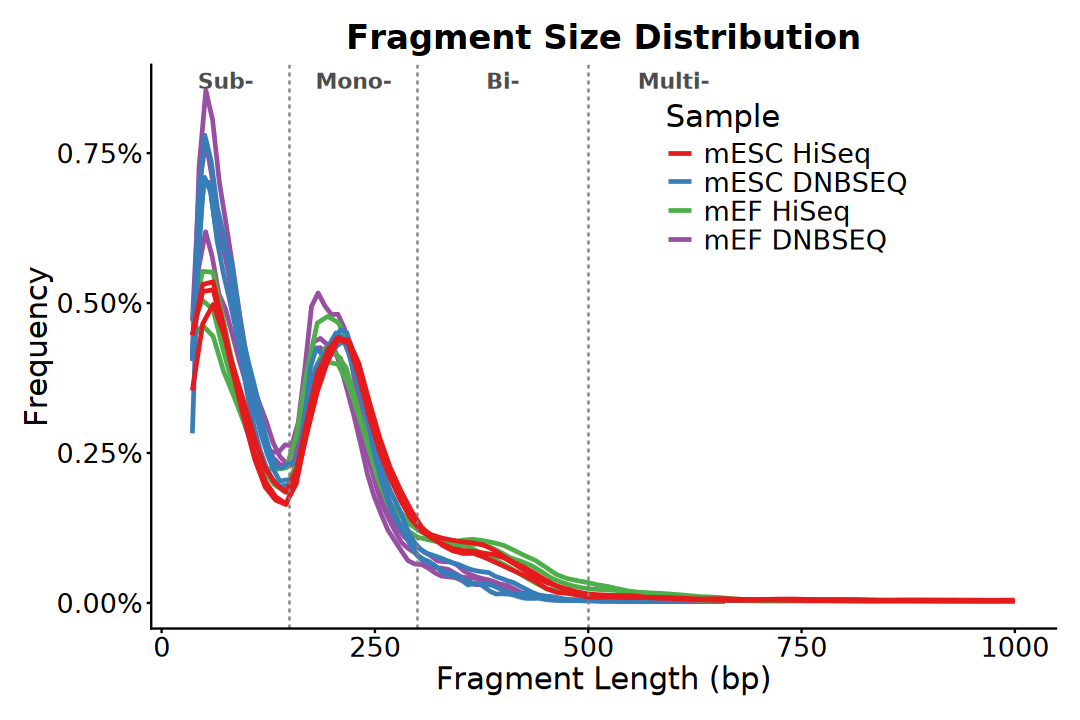

In [5]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(fragment_size, aes(x = Size, y = Freq, group = Sample)) +
    geom_smooth(
        aes(color = Group), formula = y ~ x, method = "loess", 
        na.rm = TRUE, se = FALSE, span = 0.1, linewidth = 1) +
    geom_vline(
        xintercept = c(150, 300, 500), 
        linetype = "dashed", color = "grey50", linewidth = 0.5) +
    annotate(
        "text", x = 75,  y = Inf, label = "Sub-",  vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 225, y = Inf, label = "Mono-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 400, y = Inf, label = "Bi-",   vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 600, y = Inf, label = "Multi-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    scale_color_brewer(
        palette = "Set1", labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "Fragment Size Distribution", color = "Sample",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.8),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [6]:
suppressPackageStartupMessages(library(ggpubr))

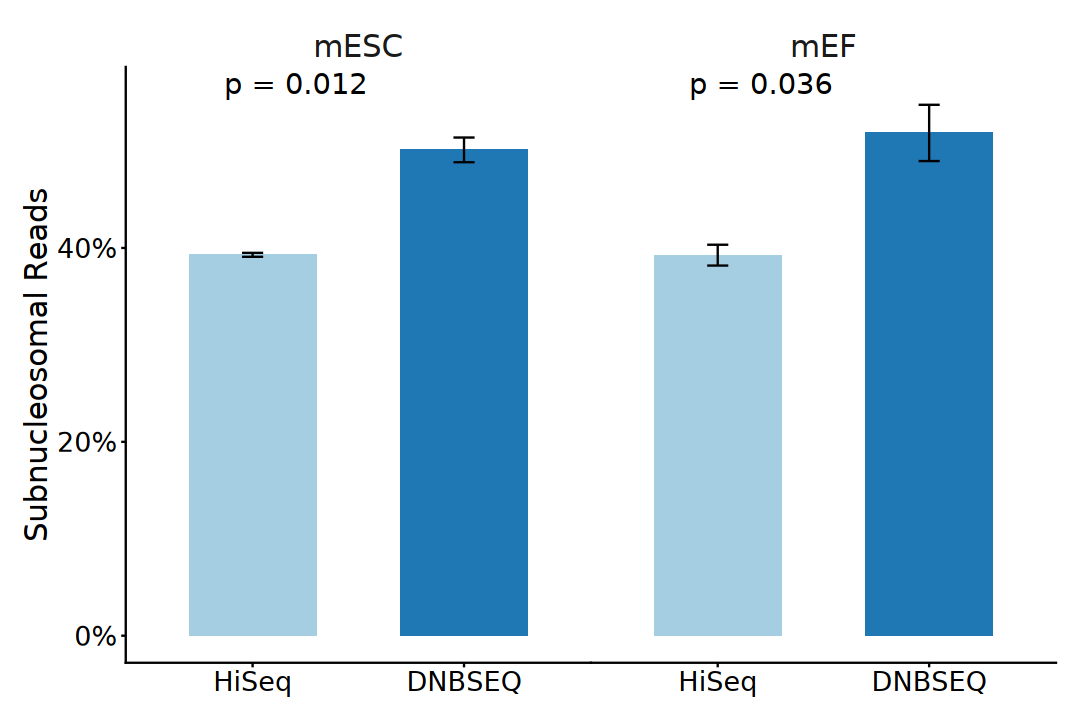

In [7]:
options(repr.plot.width = 9, repr.plot.height = 6)

fragment_size |>
    filter(Size < 150) |>
    group_by(Cell, Platform, Replicate) |>
    summarise(Ratio = sum(Freq), .groups = "drop") |>
    ungroup() |>
    ggplot(aes(x = Platform, y = Ratio, fill = Platform)) +
        geom_bar(stat = "summary", fun = mean, width = 0.6) +
        stat_summary(
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        stat_compare_means(
            aes(group = Platform), method = "t.test",
            label = "p.format", label.x = 1, size = 6) +
        facet_wrap(~ Cell, nrow = 1, strip.position = "top") +
        scale_y_continuous(labels = scales::percent_format()) +
        scale_fill_brewer(palette = "Paired") +
        labs(x = NULL, y = "Subnucleosomal Reads") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            panel.spacing.x = unit(0, "lines"),
            strip.placement = "outside",
            strip.background = element_blank(),
            strip.text = element_text(size = 18),
            legend.position = "none",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

## 3). TSS Enrichment Score

In [8]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    nbins <- length(profile)
    flank_bins <- 100 / bs

    background <- c(
        profile[1:flank_bins], 
        profile[(nbins - flank_bins + 1):nbins]) |> mean()

    norm_profile <- profile / background

    center_bin <- floor(nbins / 2)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = seq(-2000, 1990, by = bs),
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")"))
}

In [9]:
matrix_files <- file.path(data_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [10]:
profiles_list <- imap(matrix_files, compute_tss_score)

mEF_DNBSEQ_rep1 TSS Enrichment Score: 12.26

mEF_DNBSEQ_rep2 TSS Enrichment Score: 11.68

mEF_DNBSEQ_rep3 TSS Enrichment Score: 12.71

mEF_HiSeq_rep1 TSS Enrichment Score: 13.82

mEF_HiSeq_rep2 TSS Enrichment Score: 12.57

mEF_HiSeq_rep3 TSS Enrichment Score: 13.46

mESC_DNBSEQ_rep1 TSS Enrichment Score: 9.13

mESC_DNBSEQ_rep2 TSS Enrichment Score: 9.57

mESC_DNBSEQ_rep3 TSS Enrichment Score: 7.3

mESC_HiSeq_rep1 TSS Enrichment Score: 9.75

mESC_HiSeq_rep2 TSS Enrichment Score: 10.06

mESC_HiSeq_rep3 TSS Enrichment Score: 7.77



In [11]:
profile_df <- do.call(rbind, profiles_list) |>
    separate(
        Sample, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell, levels = c("mESC", "mEF")), 
        Platform = factor(Platform, levels = c("HiSeq", "DNBSEQ")),
        Replicate = factor(Replicate)) |>
    arrange(Cell, Platform, Replicate) |>
    mutate(
        Sample = forcats::fct_inorder(as.character(Sample)),
        Label = forcats::fct_inorder(as.character(Label)))

head(profile_df)

,Position,Signal,Sample,Cell,Platform,Replicate,TSS_Score,Label
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>
mESC_HiSeq_rep1.V1,-2000,23.54839,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)
mESC_HiSeq_rep1.V2,-1990,23.66942,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)
mESC_HiSeq_rep1.V3,-1980,23.70178,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)
mESC_HiSeq_rep1.V4,-1970,23.62091,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)
mESC_HiSeq_rep1.V5,-1960,23.46405,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)
mESC_HiSeq_rep1.V6,-1950,23.48961,mESC_HiSeq_rep1,mESC,HiSeq,rep1,9.746827,mESC_HiSeq_rep1 (Score: 9.75)


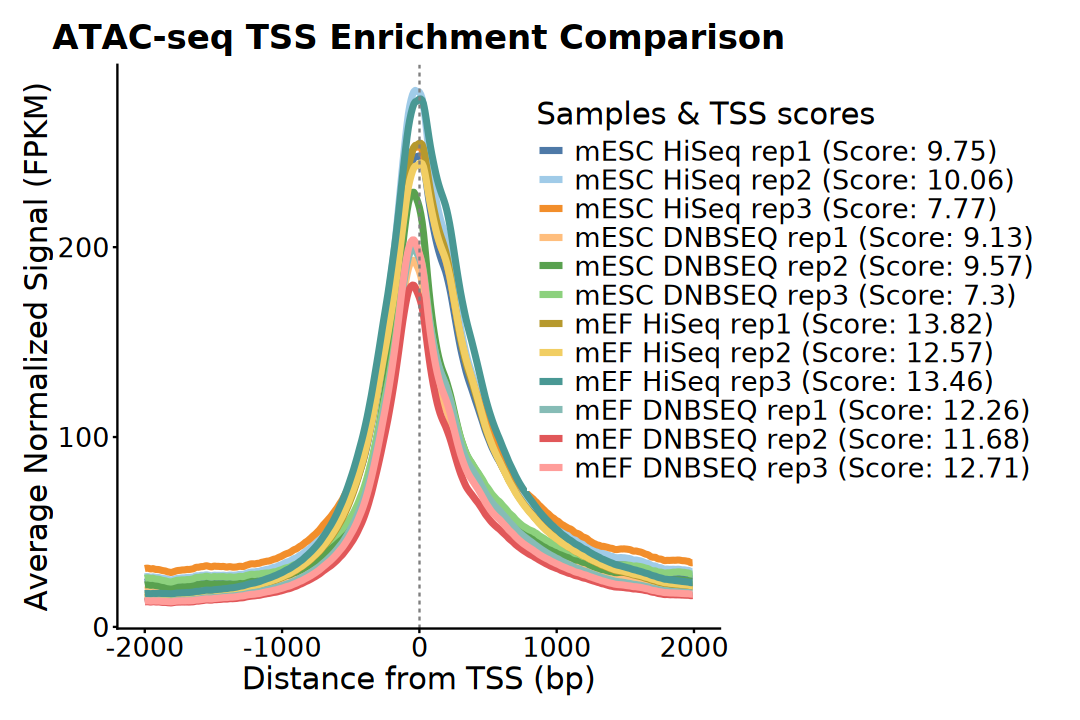

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profile_df, aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    # scale_color_viridis_d(
    #     option = "viridis", 
    #     labels = function(x) gsub("_", " ", x)) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 20", 
        labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "ATAC-seq TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal (FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 15, 1, 1), "line"),
        legend.position = "inside",
        legend.position.inside = c(1.1, 0.6),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). MACS2 Cutoff Analysis

In [13]:
cutoff_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_cutoff_analysis.txt$", full.names = TRUE) |>
    set_names(~ sub("(.*)_cutoff_analysis\\.txt$", "\\1", basename(.x)))

In [14]:
cutoff_dat <- cutoff_files |>
    map_df(~ {
        df <- read.table(.x, header = TRUE)
        df$Sample <- sub(
            "(.*)_cutoff_analysis\\.txt$", "\\1", basename(.x))
        return(df)
    }) |>
    mutate(Sample = factor(Sample, levels(profile_df$Sample)))

head(cutoff_dat)

,pscore,qscore,npeaks,lpeaks,avelpeak,Sample
,<dbl>,<dbl>,<int>,<int>,<dbl>,<fct>
1,9.9,7.90,59593,26648824,447.18,mEF_DNBSEQ_rep1
2,9.6,7.61,60500,27243280,450.30,mEF_DNBSEQ_rep1
3,9.3,7.32,62608,28191298,450.28,mEF_DNBSEQ_rep1
4,9.0,7.03,63632,28874246,453.77,mEF_DNBSEQ_rep1
5,8.7,6.74,64636,29570461,457.49,mEF_DNBSEQ_rep1
6,8.4,6.45,66986,30693834,458.21,mEF_DNBSEQ_rep1


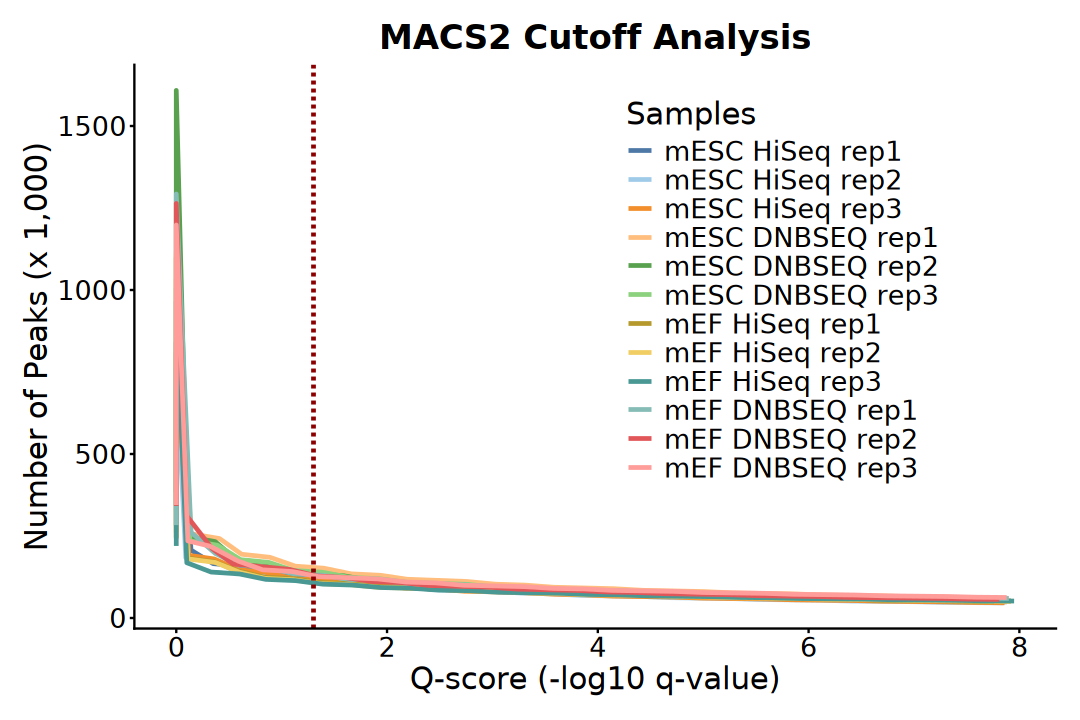

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(cutoff_dat, aes(x = qscore, y = npeaks)) +
    geom_line(
        aes(color = Sample, group = Sample), linewidth = 1) +
    geom_vline(
        xintercept = -log10(0.05), linewidth = 1, 
        linetype = "dashed", color = "darkred") +
    scale_y_continuous(labels = function(x) x / 1000) + 
    ggthemes::scale_color_tableau(
        palette = "Tableau 20", 
        labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "MACS2 Cutoff Analysis", color = "Samples",
        x = "Q-score (-log10 q-value)",
        y = "Number of Peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.6),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

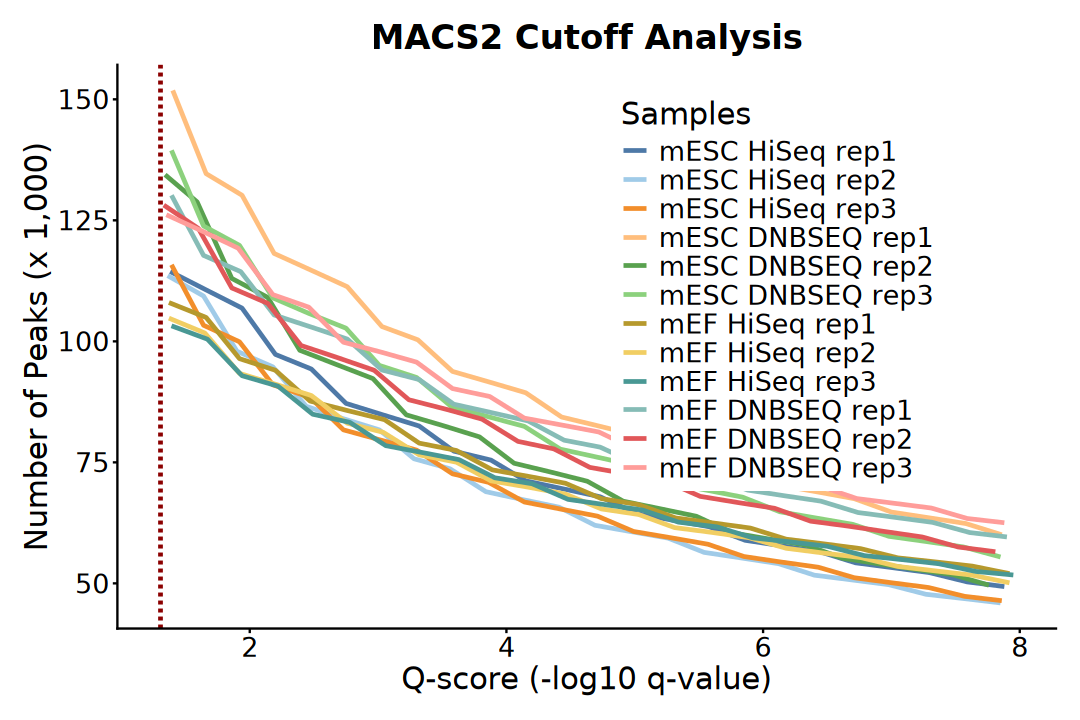

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

cutoff_dat |> 
    filter(qscore > -log10(0.05)) |>
    ggplot(aes(x = qscore, y = npeaks)) +
        geom_line(
            aes(color = Sample, group = Sample), linewidth = 1) +
        geom_vline(
            xintercept = -log10(0.05), linewidth = 1, 
            linetype = "dashed", color = "darkred") +
        scale_y_continuous(labels = function(x) x / 1000) + 
        ggthemes::scale_color_tableau(
            palette = "Tableau 20", 
            labels = function(x) gsub("_", " ", x)) +
        labs(
            title = "MACS2 Cutoff Analysis", color = "Samples",
            x = "Q-score (-log10 q-value)",
            y = "Number of Peaks (x 1,000)") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "inside",
            legend.position.inside = c(0.7, 0.6),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## 5). Sample Correlation

In [17]:
bins_mat <- file.path(data_dir, "09_count", "bins_10kb.counts.tsv") |> 
    read.table(header = TRUE, sep = "\t", comment.char = "") |>
    dplyr::rename(chr = X.chr) |>
    mutate(pos = paste0(chr, ":", start, "-", end)) |>
    select(-chr, -start, -end) |>
    column_to_rownames("pos")

In [18]:
cor_mat <- cor(bins_mat, method = "spearman")

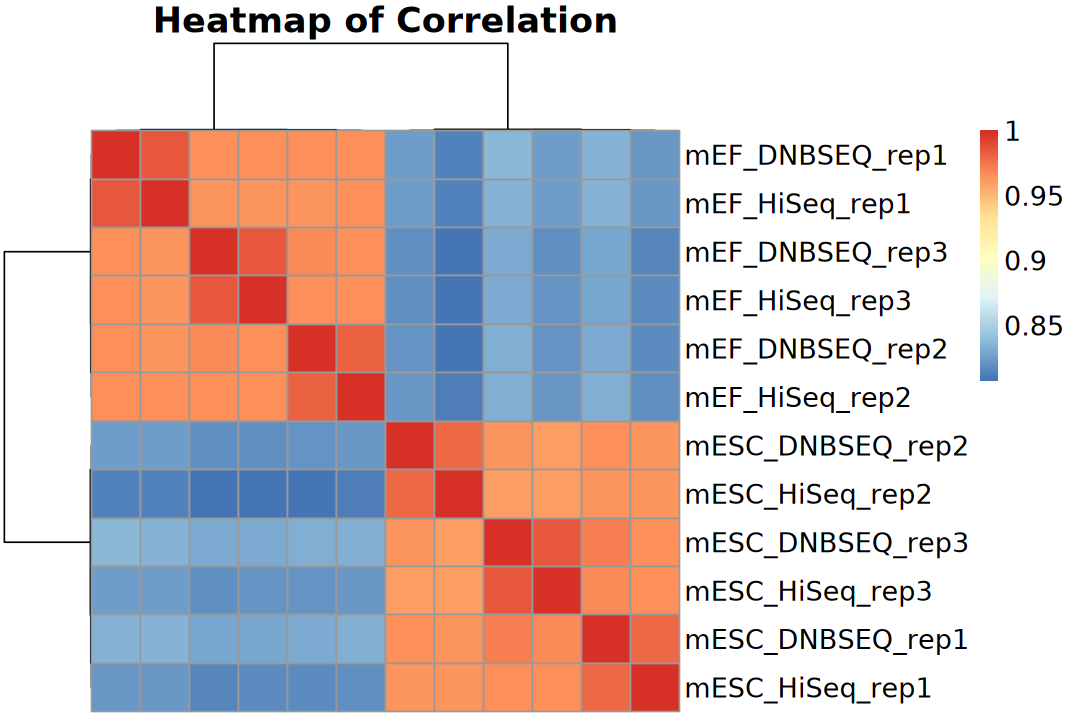

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)
pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    main = "Heatmap of Correlation", fontsize = 16,
    show_colnames = FALSE, show_rownames = TRUE)

# 3. Import Data

In [20]:
sample_order <- expand.grid(
    cell = c("mESC", "mEF"),
    platform  = c("HiSeq", "DNBSEQ"),
    replicate = c("rep1", "rep2", "rep3")) |> 
    mutate(sample = forcats::fct_cross(
        cell, platform, replicate, sep = "_")) |> 
    pull(sample) |> levels()

sample_order

[1] "mESC_HiSeq_rep1"  "mESC_HiSeq_rep2"  "mESC_HiSeq_rep3"  "mESC_DNBSEQ_rep1"
 [5] "mESC_DNBSEQ_rep2" "mESC_DNBSEQ_rep3" "mEF_HiSeq_rep1"   "mEF_HiSeq_rep2"  
 [9] "mEF_HiSeq_rep3"   "mEF_DNBSEQ_rep1"  "mEF_DNBSEQ_rep2"  "mEF_DNBSEQ_rep3"

## 1). Import narrowPeak

In [21]:
# Load macs2 narrowPeak file as GRanges
loadNarrowPeak <- function(
    file, format = "auto", keepStandardChr = TRUE, 
    dropSex = TRUE, dropMito = TRUE, blacklist = NULL) {

    if (format == "auto") {
        if (grepl("\\.narrowPeak$", file)) {
            format <- "narrowPeak"
        } else if (grepl("\\.broadPeak$", file)) {
            format <- "broadPeak"
        } else if (grepl("\\.gappedPeak$", file)) {
            format <- "gappedPeak"
        } else {
            format <- "BED"
        }
    }

    gr <- rtracklayer::import(file, format = format)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist region (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

# BRGenomics::tidyChromosomes(keep.X = FALSE, keep.Y = FALSE, keep.M = FALSE)

In [22]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> cat(sep = "\n")

mEF_DNBSEQ_rep1: mEF_DNBSEQ_rep1_peaks.narrowPeak
mEF_DNBSEQ_rep2: mEF_DNBSEQ_rep2_peaks.narrowPeak
mEF_DNBSEQ_rep3: mEF_DNBSEQ_rep3_peaks.narrowPeak
mEF_HiSeq_rep1: mEF_HiSeq_rep1_peaks.narrowPeak
mEF_HiSeq_rep2: mEF_HiSeq_rep2_peaks.narrowPeak
mEF_HiSeq_rep3: mEF_HiSeq_rep3_peaks.narrowPeak
mESC_DNBSEQ_rep1: mESC_DNBSEQ_rep1_peaks.narrowPeak
mESC_DNBSEQ_rep2: mESC_DNBSEQ_rep2_peaks.narrowPeak
mESC_DNBSEQ_rep3: mESC_DNBSEQ_rep3_peaks.narrowPeak
mESC_HiSeq_rep1: mESC_HiSeq_rep1_peaks.narrowPeak
mESC_HiSeq_rep2: mESC_HiSeq_rep2_peaks.narrowPeak
mESC_HiSeq_rep3: mESC_HiSeq_rep3_peaks.narrowPeak


In [23]:
peaks_list <- lapply(
    peaks_files, loadNarrowPeak, 
    dropSex = FALSE, blacklist = blacklist_file)
peaks_list <- peaks_list[sample_order]

In [24]:
peaks_list[1]

$mESC_HiSeq_rep1
GRanges object with 97099 ranges and 6 metadata columns:
          seqnames              ranges strand |                   name
             <Rle>           <IRanges>  <Rle> |            <character>
      [1]     chr1     3037780-3038205      * | mESC_HiSeq_rep1_peak..
      [2]     chr1     3062487-3063142      * | mESC_HiSeq_rep1_peak..
      [3]     chr1     3147439-3147777      * | mESC_HiSeq_rep1_peak..
      [4]     chr1     3482684-3483642      * | mESC_HiSeq_rep1_peak..
      [5]     chr1     3531621-3532044      * | mESC_HiSeq_rep1_peak..
      ...      ...                 ...    ... .                    ...
  [97095]     chrX 169857687-169858098      * | mESC_HiSeq_rep1_peak..
  [97096]     chrX 169879413-169880360      * | mESC_HiSeq_rep1_peak..
  [97097]     chrY       809124-809517      * | mESC_HiSeq_rep1_peak..
  [97098]     chrY     1010242-1010493      * | mESC_HiSeq_rep1_peak..
  [97099]     chrY     1245399-1245854      * | mESC_HiSeq_rep1_peak..
   

## 2). Import bigwig

In [25]:
# Load bigwig (bw) file as GRanges
loadBigwig <- function(
    file, keepStandardChr = TRUE, 
    dropSex = TRUE, dropMito = TRUE, blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }        
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

# BRGenomics::tidyChromosomes(keep.X = FALSE, keep.Y = FALSE, keep.M = FALSE)

In [26]:
signals_files <- file.path(data_dir, "07_bigwig") |>
    list.files(pattern = "\\.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bw$", "\\1", basename(.x))) |>
    (\(files) files[!grepl("bin1", files)])()

paste(names(signals_files), basename(signals_files), sep = ": ") |> cat(sep = "\n")

mEF_DNBSEQ_rep1: mEF_DNBSEQ_rep1.bw
mEF_DNBSEQ_rep2: mEF_DNBSEQ_rep2.bw
mEF_DNBSEQ_rep3: mEF_DNBSEQ_rep3.bw
mEF_HiSeq_rep1: mEF_HiSeq_rep1.bw
mEF_HiSeq_rep2: mEF_HiSeq_rep2.bw
mEF_HiSeq_rep3: mEF_HiSeq_rep3.bw
mESC_DNBSEQ_rep1: mESC_DNBSEQ_rep1.bw
mESC_DNBSEQ_rep2: mESC_DNBSEQ_rep2.bw
mESC_DNBSEQ_rep3: mESC_DNBSEQ_rep3.bw
mESC_HiSeq_rep1: mESC_HiSeq_rep1.bw
mESC_HiSeq_rep2: mESC_HiSeq_rep2.bw
mESC_HiSeq_rep3: mESC_HiSeq_rep3.bw


In [27]:
signals_list <- lapply(
    signals_files, loadBigwig, 
    dropSex = FALSE, blacklist = blacklist_file)
signals_list <- signals_list[sample_order]

In [28]:
signals_list[1]

$mESC_HiSeq_rep1
GRanges object with 26607269 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3000120      * |    0.0000
         [2]     chr1   3000121-3000340      * |    3.5844
         [3]     chr1   3000341-3003250      * |    0.0000
         [4]     chr1   3003251-3003410      * |    3.5844
         [5]     chr1   3003411-3003490      * |    7.1688
         ...      ...               ...    ... .       ...
  [26607265]     chrY 41154471-41154480      * |    3.5844
  [26607266]     chrY 41154481-41154630      * |    0.0000
  [26607267]     chrY 41154631-41154690      * |    3.5844
  [26607268]     chrY 41154691-41158490      * |    0.0000
  [26607269]     chrY 41158491-41158550      * |    3.5844
  -------
  seqinfo: 21 sequences from an unspecified genome


# 4. Chromatin Accessibility Pattern

## 1). Number of Peaks

In [29]:
coldata <- tibble(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell, levels = c("mESC", "mEF")),
        Platform = factor(Platform, levels = c("HiSeq", "DNBSEQ")),
        Group = forcats::fct_cross(Cell, Platform, sep = "_"),
        Replicate = factor(Replicate),
        Number = lengths(peaks_list)) |>
    arrange(Cell, Platform, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Platform,Replicate,Group,Number
,<fct>,<fct>,<fct>,<fct>,<int>
mESC_HiSeq_rep1,mESC,HiSeq,rep1,mESC_HiSeq,97099
mESC_HiSeq_rep2,mESC,HiSeq,rep2,mESC_HiSeq,94471
mESC_HiSeq_rep3,mESC,HiSeq,rep3,mESC_HiSeq,96610
mESC_DNBSEQ_rep1,mESC,DNBSEQ,rep1,mESC_DNBSEQ,126640
mESC_DNBSEQ_rep2,mESC,DNBSEQ,rep2,mESC_DNBSEQ,108755
mESC_DNBSEQ_rep3,mESC,DNBSEQ,rep3,mESC_DNBSEQ,116289
mEF_HiSeq_rep1,mEF,HiSeq,rep1,mEF_HiSeq,94398
mEF_HiSeq_rep2,mEF,HiSeq,rep2,mEF_HiSeq,91381
mEF_HiSeq_rep3,mEF,HiSeq,rep3,mEF_HiSeq,91116


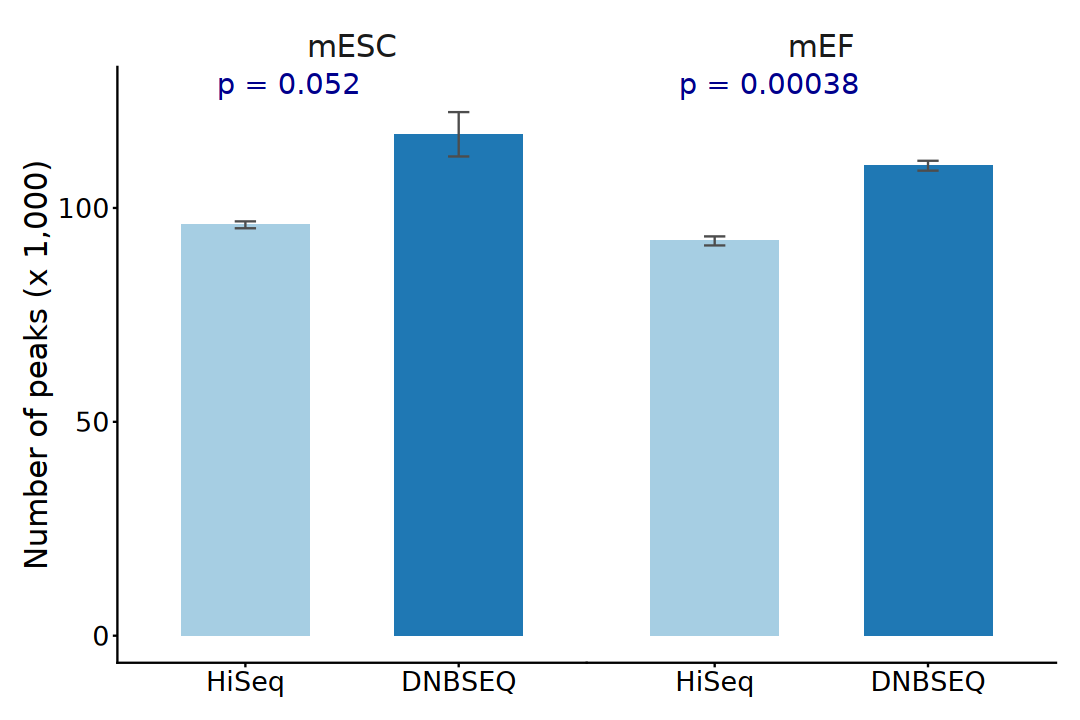

In [30]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(coldata, aes(x = Platform, y = Number, fill = Platform)) +
    geom_bar(stat = "summary", fun = mean, width = 0.6) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar",
        col = "grey30", width = 0.1) +
    stat_compare_means(
        aes(group = Platform), method = "t.test", label = "p.format",
        label.x = 1, size = 6, col = "darkblue") +
    facet_wrap(~ Cell, nrow = 1, strip.position = "top") +
    scale_y_continuous(labels = function(x) x / 1000) +
    scale_fill_brewer(palette = "Paired") +
    labs(x = NULL, y = "Number of peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"),
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Replicate Consistency

In [31]:
suppressPackageStartupMessages(library(ChIPpeakAnno))

In [32]:
# ------------------------------------------------------------------------------
# Function: summarize_replicate_peak_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of peak sets 
# across biological or technical replicates within a given experimental group.
# ------------------------------------------------------------------------------
summarize_replicate_peak_overlaps <- function(prefix, peaks_list) {

    # 1. Identify sample names in peaks_list that match the current group prefix
    sample_names <- grep(
        paste0("^", prefix, "_rep"), names(peaks_list), value = TRUE)
    rep_id <- str_replace_all(sample_names, paste0(prefix, "_"), "")

    # 2. Generate all possible combination levels of replicates
    comb_levels <- unlist(lapply(seq_along(rep_id), function(i) {
        combn(rep_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)

    # 4. Calculate intersections/overlaps among peak sets using ChIPpeakAnno
    ol <- peaks_list[sample_names] |> 
        lapply(function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
        findOverlapsOfPeaks()

    # 5. Extract and clean the Venn counts matrix into a tidy data frame
    ol$venn_cnt[, c(sample_names, "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        rename_with(
            .fn = ~ str_replace_all(., paste0(prefix, "_"), ""),
            .cols = everything()) |>
        rowwise() |>
        mutate(
            Combination = {
                vals <- c_across(all_of(rep_id))
                present <- rep_id[vals == 1]
                if (length(present) == 0) "none" else 
                    paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |>
        ungroup() |>
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |>
        as.data.frame()
}

In [33]:
# ~ 8 minutes
replicate_peak_df <- map_df(
    levels(coldata$Group), function(x) {
        message("Processing Group: ", x)
        summarize_replicate_peak_overlaps(x, peaks_list)
}) |> 
    mutate(Group = factor(Group, levels = levels(coldata$Group)) |>
        forcats::fct_relabel(~ str_replace_all(.x, "_", "\n")))

Processing Group: mESC_HiSeq



Processing Group: mESC_DNBSEQ

Processing Group: mEF_HiSeq

Processing Group: mEF_DNBSEQ



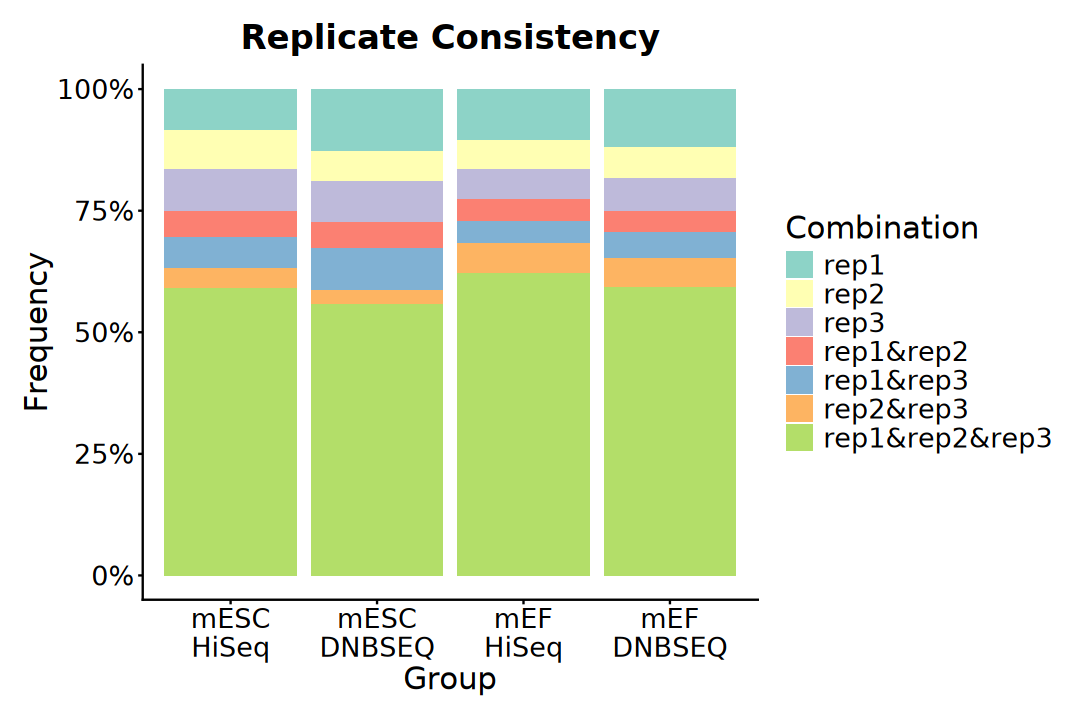

In [34]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(replicate_peak_df, aes(x = Group, y = Counts)) +
    geom_bar(aes(fill = Combination), stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = "Group", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). Peaks Annotation

In [35]:
# load reference gene anntotion
gtf <- import(gtf_file) |> 
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

standard_chromosome <- seqinfo(gtf) |> seqnames()

In [36]:
# txdb <- txdbmaker::makeTxDbFromGFF(
#     gtf_file, dataSource = "Gencode", 
#     organism = "Mus musculus", taxonomyId = 10090, 
#     metadata = data.frame(
#         name = c("Genome", "Gencode Release"), 
#         value = c("mm10", "vM23")))

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"


In [37]:
blacklist <- rtracklayer::import(blacklist_file)
blacklist

GRanges object with 3435 ranges and 1 metadata column:
         seqnames            ranges strand |               name
            <Rle>         <IRanges>  <Rle> |        <character>
     [1]    chr10         1-3135400      * | High Signal Region
     [2]    chr10   3218901-3276600      * |    Low Mappability
     [3]    chr10   3576901-3627700      * |    Low Mappability
     [4]    chr10   4191101-4197600      * |    Low Mappability
     [5]    chr10   4613501-4615400      * | High Signal Region
     ...      ...               ...    ... .                ...
  [3431]     chrY   6530201-6663200      * | High Signal Region
  [3432]     chrY   6760201-6835800      * | High Signal Region
  [3433]     chrY   6984101-8985400      * | High Signal Region
  [3434]     chrY 10638501-41003800      * | High Signal Region
  [3435]     chrY 41159201-91744600      * | High Signal Region
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

### a). ChIPseeker

In [38]:
suppressPackageStartupMessages(library(ChIPseeker))

In [39]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c(
        "Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


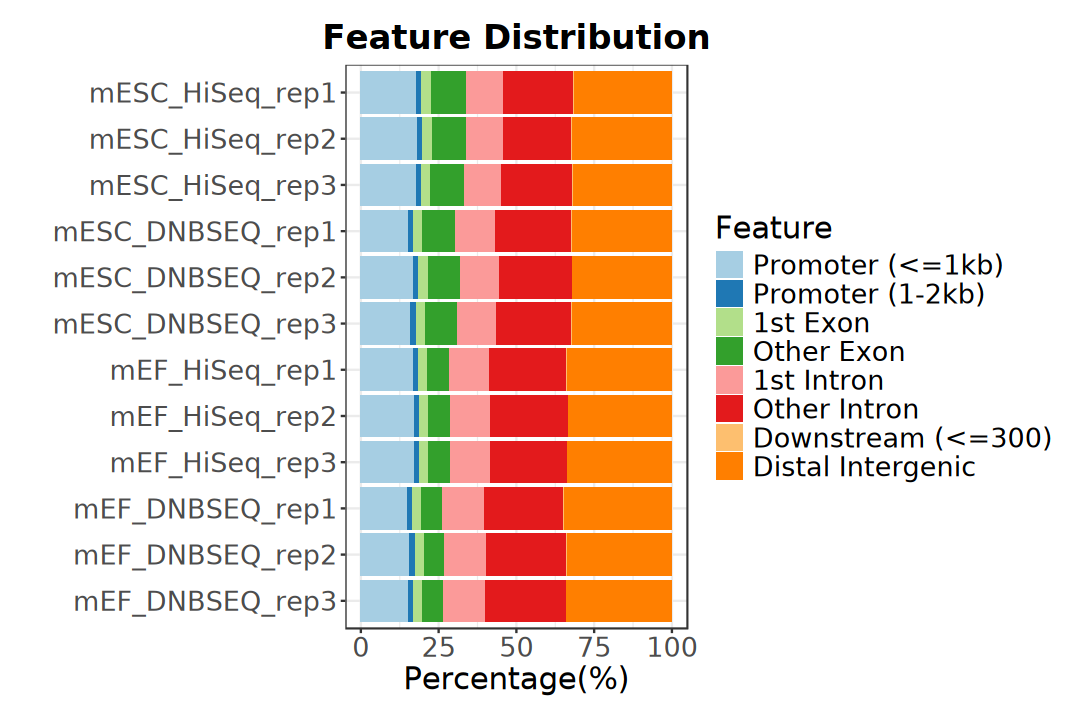

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

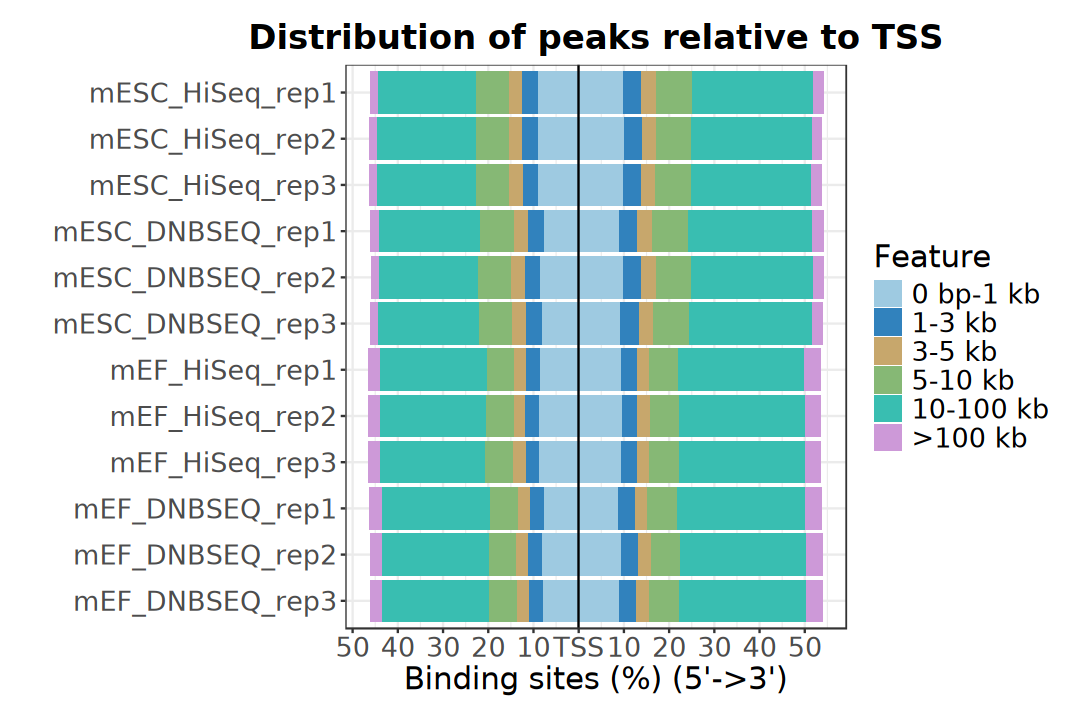

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDistToTSS(peaks_anno_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [42]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno@annoStat |>
    mutate(
        MergedFeature = case_when(
            Feature %in% c(
                "Promoter (<=1kb)", "Promoter (1-2kb)") ~ "Promoter",
            Feature %in% c(
                "1st Exon", "Other Exon") ~ "Exon",
            Feature %in% c(
                "1st Intron", "Other Intron") ~ "Intron",
            Feature %in% c(
                "Downstream (<=300)", "Distal Intergenic") ~ "Intergenic",
            TRUE ~ as.character(Feature))) |>
    group_by(MergedFeature) |> 
    summarise(Frequency = sum(Frequency)) |>
    ungroup()
})

In [43]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

head(anno_stats_combined)

Sample,MergedFeature,Frequency
<fct>,<fct>,<dbl>
mESC_HiSeq_rep1,Exon,14.38223
mESC_HiSeq_rep1,Intergenic,31.58941
mESC_HiSeq_rep1,Intron,34.38552
mESC_HiSeq_rep1,Promoter,19.64284
mESC_HiSeq_rep2,Exon,14.16625
mESC_HiSeq_rep2,Intergenic,32.17813


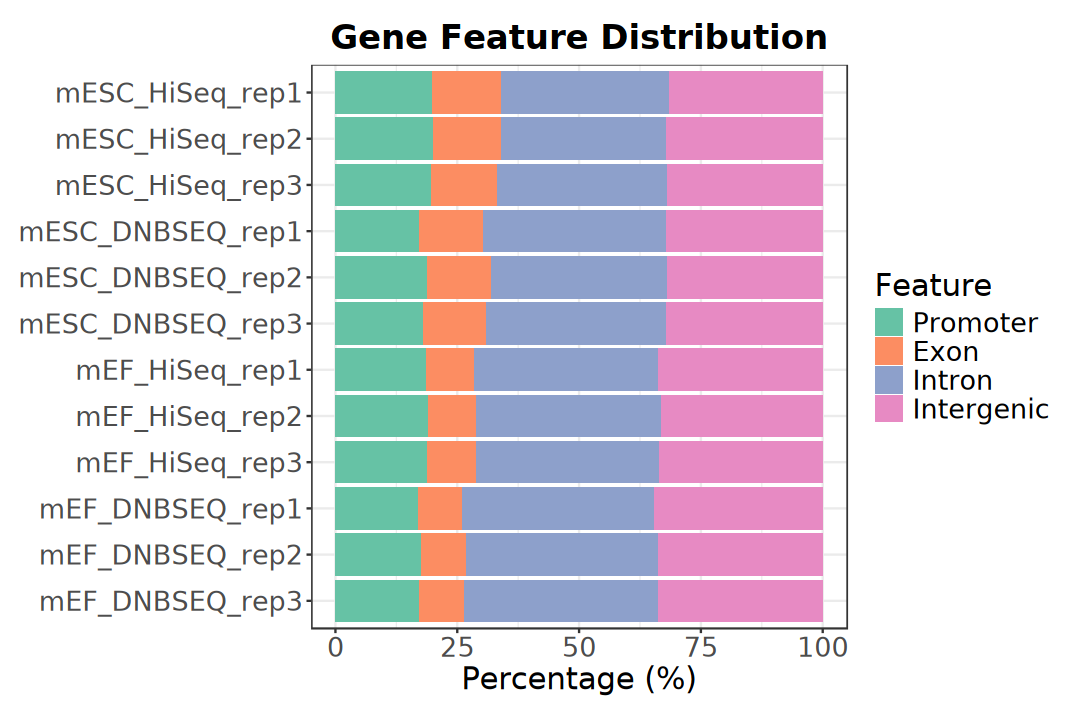

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). ChIPpeakAnno

In [45]:
suppressPackageStartupMessages(library(ChIPpeakAnno))

In [46]:
peaks_anno_list <- lapply(
    peaks_list, assignChromosomeRegion, 
    TxDb = txdb, nucleotideLevel = FALSE,
    proximal.promoter.cutoff = c(upstream = 2000, downstream = 500),
    immediate.downstream.cutoff = c(upstream = 0, downstream = 0),
    precedence = c(
        "Promoters", "fiveUTRs", "threeUTRs", "Exons", 
        "Introns", "immediateDownstream"))

In [47]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno$percentage |>
        as.data.frame() |>
        rownames_to_column(var = "Feature") |>
        mutate(
            MergedFeature = case_when(
                Feature %in% c(
                    "Promoters") ~ "Promoter",
                Feature %in% c(
                    "Exons", "fiveUTRs", "threeUTRs") ~ "Exon",
                Feature %in% c(
                    "Introns") ~ "Intron",
                Feature %in% c(
                    "immediateDownstream", "Intergenic.Region") ~ "Intergenic",
                TRUE ~ as.character(Feature))) |>
        group_by(MergedFeature) |> 
        summarise(Frequency = sum(`anno$percentage`)) |>
        ungroup()
})

In [48]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

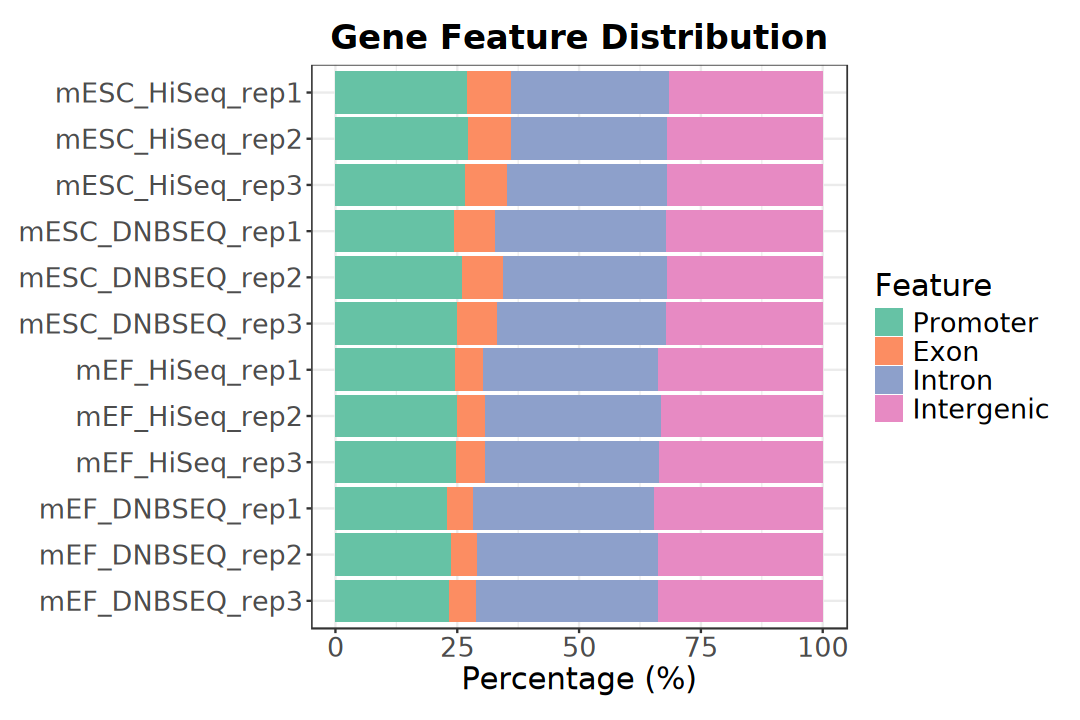

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### c). Manual

In [50]:
feature_list <- list(
    TSS = gtf[gtf$type == "gene", ] |> 
        promoters(upstream = 0, downstream = 1),
    Promoter = gtf[gtf$type == "gene", ] |>
        promoters(upstream = 2000, downstream = 500),
    Exon = gtf[gtf$type == "exon", ],
    Intron = GenomicFeatures::intronsByTranscript(
        txdb, use.names = TRUE) |> 
        unlist()
)

In [51]:
# ------------------------------------------------------------------------------
# Function: annotate_peaks_with_genomic_features
#
# Description:
# This function performs hierarchical genomic annotation of peak regions 
# (GRanges) based on predefined genomic feature categories and computes the 
# strand-aware signed distance to the nearest transcription start site (TSS).
# ------------------------------------------------------------------------------

annotate_peaks_with_genomic_features <- function(
    peaks, featureList, sameStrand = FALSE, 
    precedence = c("Promoter", "Exon", "Intron", "Intergenic")) {

    peaks$Annotation <- "Intergenic"
    precedence <- precedence[precedence != "Intergenic"]

    for (feature in rev(precedence)) {
        if (!feature %in% names(featureList)) next
        hits <- overlapsAny(
            peaks, featureList[[feature]], ignore.strand = !sameStrand)
        peaks$Annotation[hits] <- feature
    }

    idx <- nearest(
        peaks, featureList[["TSS"]], ignore.strand = !sameStrand)

    peak_center <- start(peaks) + 
        ifelse(
            "peak" %in% colnames(mcols(peaks)), 
            peaks$peak, round(width(peaks)/2))

    tss_coord <- start(featureList[["TSS"]])[idx]
    tss_str <- as.vector(strand(featureList[["TSS"]]))[idx]

    dist <- peak_center - tss_coord
    dist[tss_str == "-"] <- -dist[tss_str == "-"]
    dist[is.na(idx)] <- NA_integer_

    peaks$SignedDistToTSS <- dist

    return(peaks)
}

In [52]:
peaks_anno_list <- lapply(
    peaks_list, annotate_peaks_with_genomic_features, 
    featureList = feature_list)

In [53]:
anno_stats <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    gr$Annotation |> table() |>
        as.data.frame() |>
        mutate(
            MergedFeature = Var1, 
            Frequency = Freq,
            Sample = sample_name) |>
        select(MergedFeature, Frequency, Sample)
})

In [54]:
anno_stats_combined <- bind_rows(anno_stats) |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

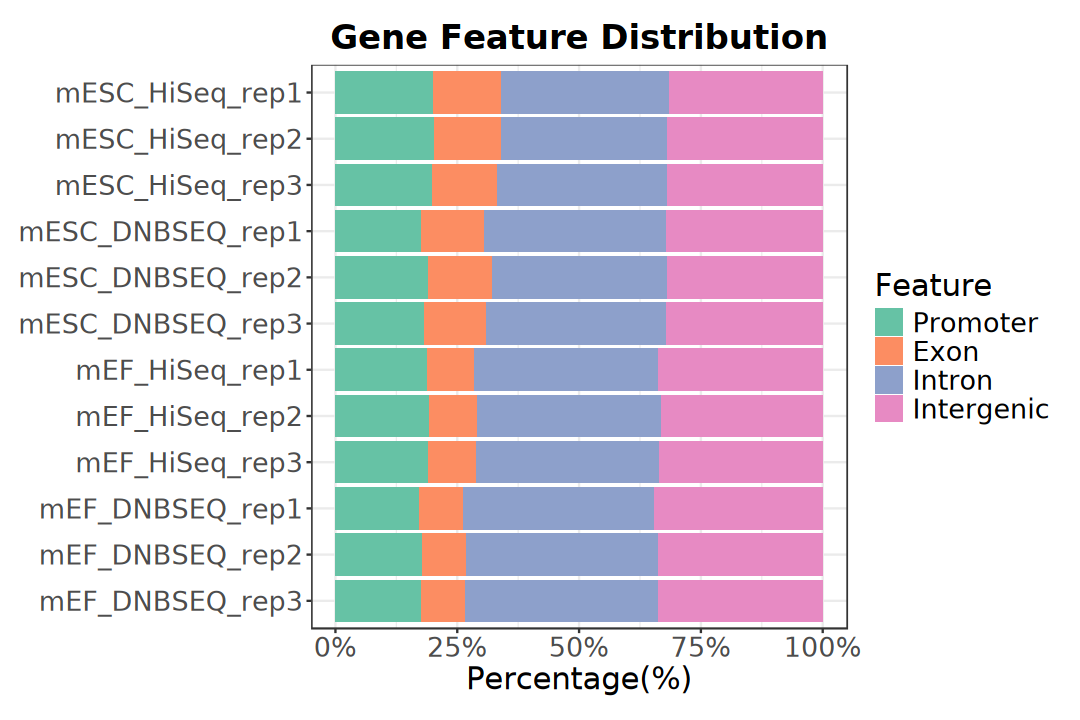

In [55]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_fill(reverse = TRUE)) +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage(%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [56]:
combined_df <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    df <- as.data.frame(gr)
    df$Sample <- sample_name
    return(df)
})

plot_df <- combined_df |>
    mutate(distance = abs(SignedDistToTSS)) |>
    mutate(Group = case_when(
        distance <= 1000 ~ "<= 1kb",
        distance > 1000 & distance <= 3000 ~ "1 - 3kb",
        distance > 3000 & distance <= 10000 ~ "3 - 10kb",
        distance > 10000 ~ "> 10kb")) |>
    mutate(Group = factor(
        Group, levels = c(
            "<= 1kb", "1 - 3kb", "3 - 10kb", "> 10kb"))) |>
    group_by(Sample, Group) |>
    tally() |>
    mutate(Percentage = n / sum(n) * 100)

head(plot_df)

Sample,Group,n,Percentage
<chr>,<fct>,<int>,<dbl>
mEF_DNBSEQ_rep1,<= 1kb,17251,15.409695
mEF_DNBSEQ_rep1,1 - 3kb,8322,7.433742
mEF_DNBSEQ_rep1,3 - 10kb,20384,18.208291
mEF_DNBSEQ_rep1,> 10kb,65992,58.948271
mEF_DNBSEQ_rep2,<= 1kb,17620,16.323884
mEF_DNBSEQ_rep2,1 - 3kb,8257,7.649620


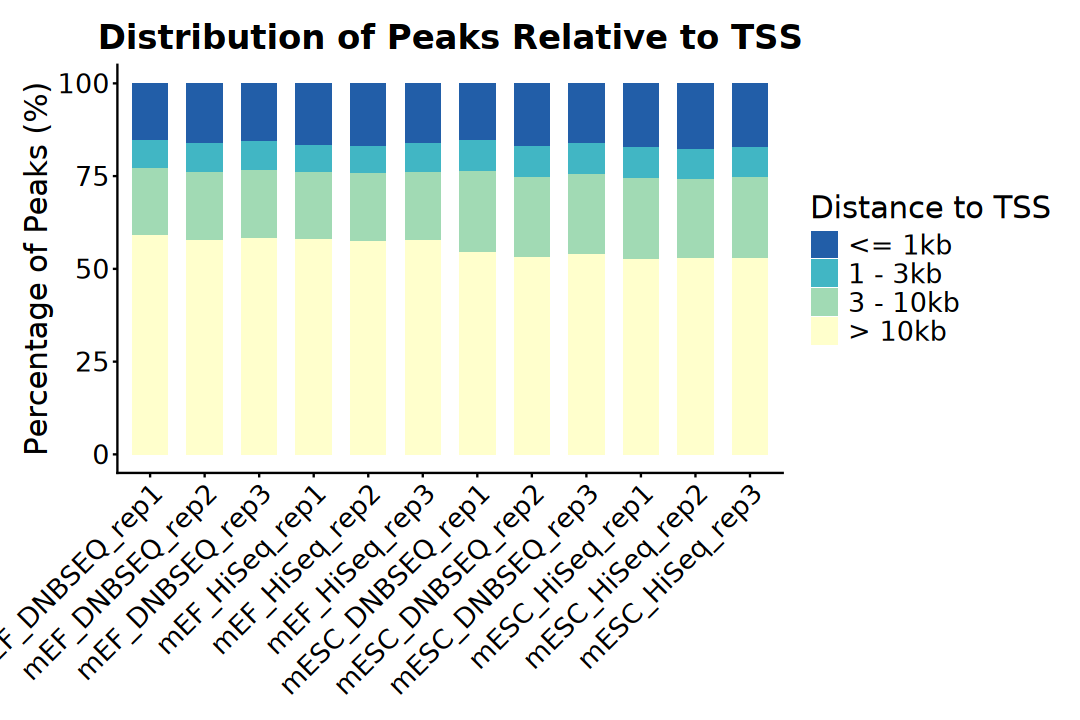

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = Percentage, fill = Group)) +
     geom_bar(stat = "identity", position = "stack", width = 0.65) +
     scale_fill_brewer(palette = "YlGnBu", direction = -1) + 
     labs(
          title = "Distribution of Peaks Relative to TSS",
          x = NULL, y = "Percentage of Peaks (%)",
          fill = "Distance to TSS") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 16))

## 4). Handling Replicates

### a). bedtools

> Run `get_high_confidence_consensus_peaks.sh`

In [58]:
peaks_files <- file.path(data_dir, "05_peaks", "consensus") |>
    list.files(pattern = "^m.*_.*\\.consensus\\.bed$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.consensus\\.bed$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> cat(sep = "\n")

mEF_DNBSEQ: mEF_DNBSEQ.consensus.bed
mEF_HiSeq: mEF_HiSeq.consensus.bed
mESC_DNBSEQ: mESC_DNBSEQ.consensus.bed
mESC_HiSeq: mESC_HiSeq.consensus.bed


In [59]:
consensus_list <- lapply(
    peaks_files, loadNarrowPeak, 
    dropSex = FALSE, blacklist = blacklist_file)

Missing totalTest! totalTest is required for HyperG test. 
If totalTest is missing, pvalue will be calculated by estimating 
the total binding sites of encoding region of human.
totalTest = humanGenomeSize * (2%(codingDNA) + 
             1%(regulationRegion)) / ( 2 * averagePeakWidth )
          = 3.3e+9 * 0.03 / ( 2 * averagePeakWidth)
          = 5e+7 /averagePeakWidth



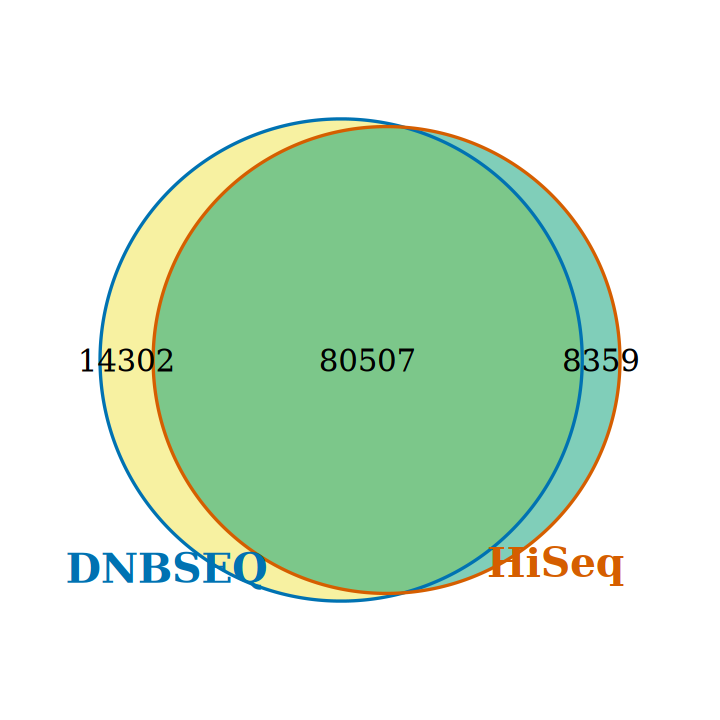

In [60]:
options(repr.plot.width = 6, repr.plot.height = 6)

veen <- makeVennDiagram(
    Peaks = list(consensus_list$mESC_HiSeq, consensus_list$mESC_DNBSEQ), 
    NameOfPeaks = c("HiSeq", "DNBSEQ"), 
    cex = 1.5, cat.cex = 2, cat.fontface = "bold", 
    cat.pos = c(-40, 40), alpha = 0.5,
    fill = c("#009E73", "#F0E442"), 
    col = c("#D55E00", "#0072B2"), 
    cat.col = c("#D55E00", "#0072B2"), 
    margin = 0.08)

Missing totalTest! totalTest is required for HyperG test. 
If totalTest is missing, pvalue will be calculated by estimating 
the total binding sites of encoding region of human.
totalTest = humanGenomeSize * (2%(codingDNA) + 
             1%(regulationRegion)) / ( 2 * averagePeakWidth )
          = 3.3e+9 * 0.03 / ( 2 * averagePeakWidth)
          = 5e+7 /averagePeakWidth



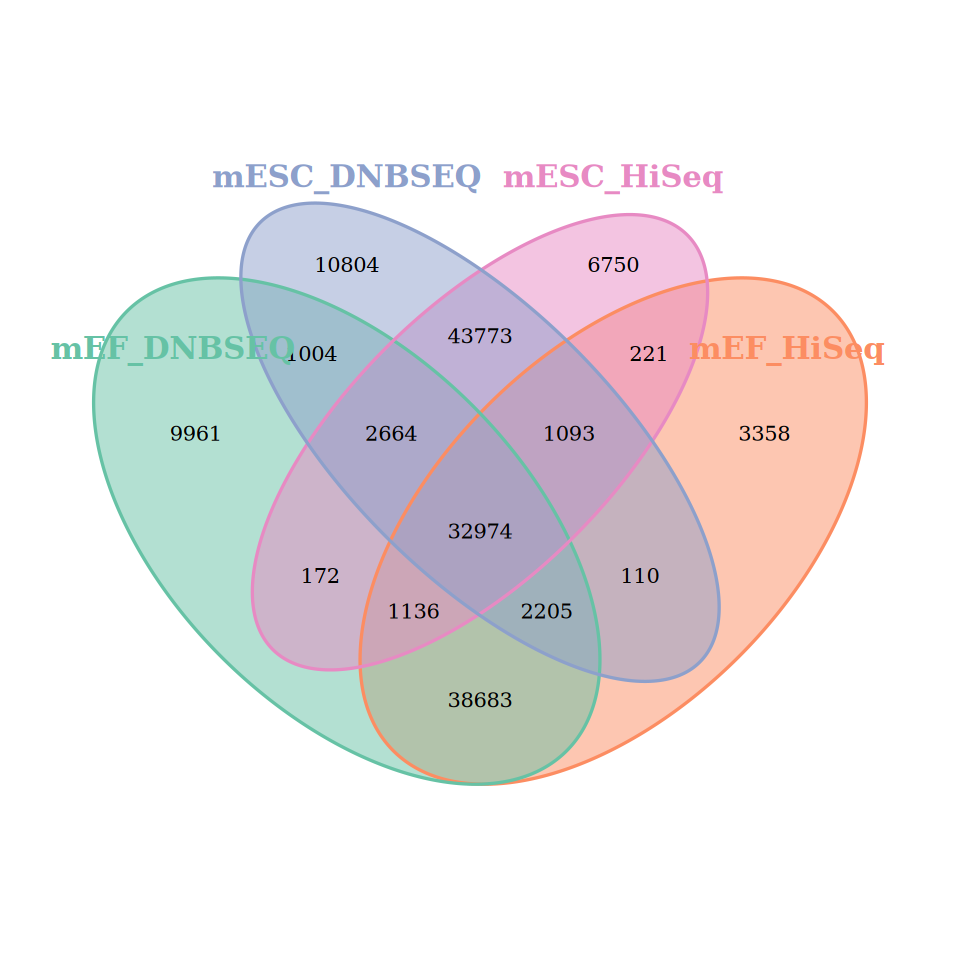

In [61]:
options(repr.plot.width = 8, repr.plot.height = 8)

colors_4 <- brewer.pal(4, "Set2")

venn <- makeVennDiagram(
    Peaks = consensus_list, NameOfPeaks = names(consensus_list),
    cex = 1, cat.cex = 1.5, cat.fontface = "bold", 
    cat.dist = 0.1, alpha = 0.5,
    fill = colors_4, col = colors_4, cat.col = colors_4,
    margin = 0.1)

### b). GenomicRanges

### c). IDR

In [62]:
# library(idr)

### d). MSPC & rMSPC

In [63]:
# library(rmspc)

# mspc_results <- mspc(
#     input = peaks_list, replicateType = "Biological",
#     stringencyThreshold = 1e-8, weakThreshold = 1e-4, 
#     gamma = 1e-8, c = 2, alpha = 0.05, 
#     multipleIntersections = "Lowest", 
#     keep = FALSE, GRanges = TRUE)

## 5). Metagene Profile (Peaks)

In [64]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

### a). EnrichedHeatmap

In [65]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [66]:
peaks_gene_mat_list <- lapply(
    peaks_list[1:6], normalizeToMatrix, GENES, 
    mean_mode = "coverage", extend = 2000, w = 50,
    background = 0, target_ratio = 0.4)

In [67]:
mean_mat <- Reduce("+", peaks_gene_mat_list) / length(peaks_gene_mat_list)
attributes(mean_mat) <- attributes(peaks_gene_mat_list[[1]])

unified_row_order <- order(rowSums(mean_mat), decreasing = TRUE)

In [68]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(peaks_gene_mat_list)) |> 
    setNames(names(peaks_gene_mat_list))

col_funs <- lapply(names(peaks_gene_mat_list), function(mark) {
    unname(c("#ffffff", base_colors[mark]))
})

names(col_funs) <- names(peaks_gene_mat_list)

In [ ]:
# max_signal <- unlist(gene_mat_list, use.names = FALSE) |>
#     quantile(0.95, na.rm = TRUE)

# unified_cols <- circlize::colorRamp2(
#     c(0, max_signal), c("#F5F5F5", "#ff3f56"))

In [69]:
ht_list <- NULL

for (i in seq_len(length(peaks_gene_mat_list))) {
    mark_name <- names(peaks_gene_mat_list)[i]
    ht_list <- ht_list + EnrichedHeatmap(
        peaks_gene_mat_list[[i]], 
        name = mark_name,
        column_title = mark_name, 
        col = col_funs[[mark_name]],
        cluster_rows = FALSE,
        row_order = unified_row_order,
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = base_colors[mark_name]), 
                ylim = c(0, 0.8), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        show_heatmap_legend = (i == 1),
        heatmap_legend_param = list(
            direction = "horizontal",
            title_position = "topcenter",
            legend_width = unit(4, "cm")),
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)
}

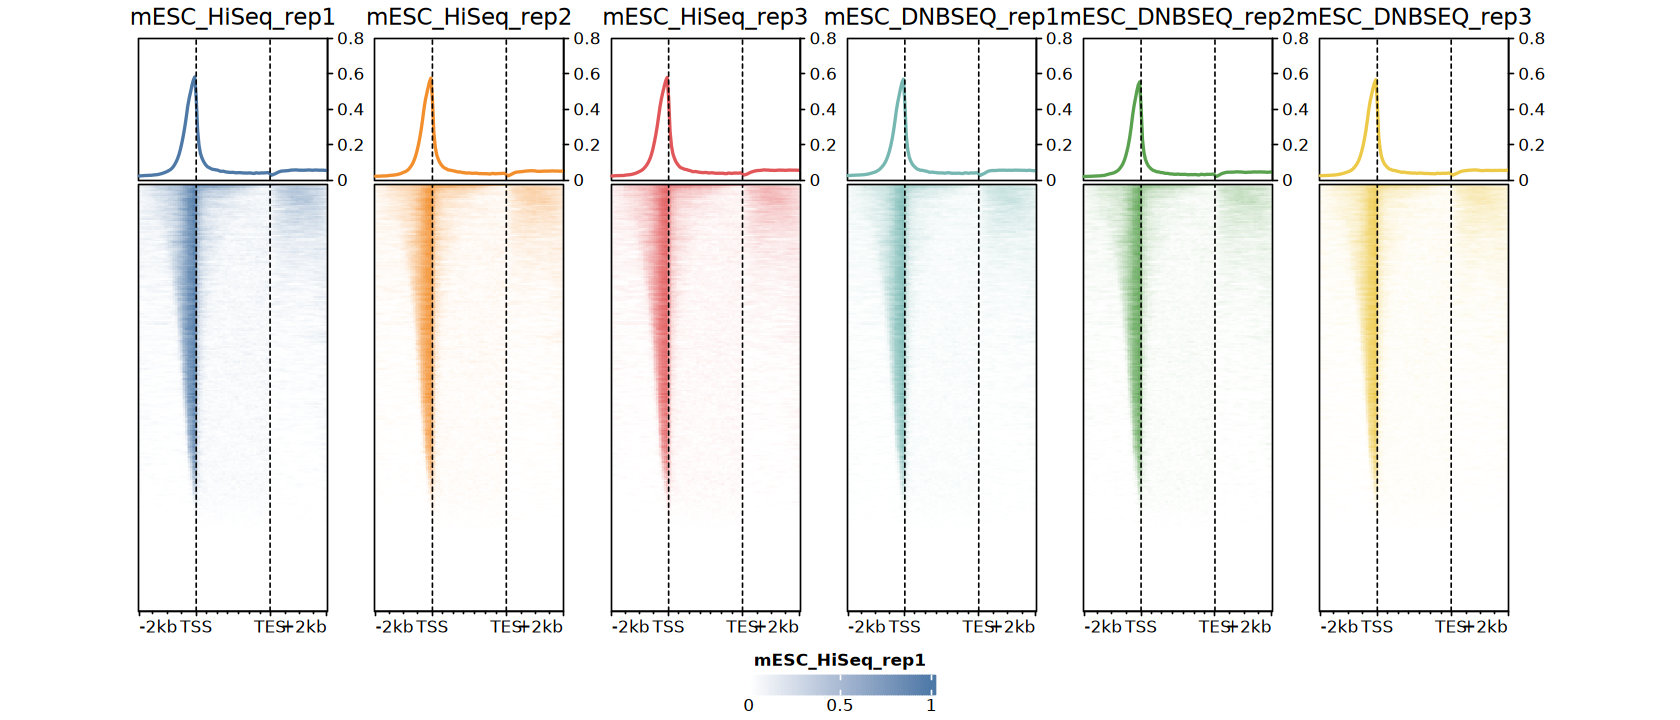

In [70]:
options(repr.plot.width = 14, repr.plot.height = 6)

draw(
    ht_list, 
    heatmap_legend_side = "bottom",
    ht_gap = unit(rep(10, length(peaks_gene_mat_list)), "mm"))

In [71]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

profiles_df <- purrr::imap_dfr(
    peaks_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Coverage = colMeans(.x, na.rm = TRUE))) |>
    mutate(Sample = forcats::fct_inorder(as.character(Sample)))

head(profiles_df)

Position,Sample,Coverage
<fct>,<fct>,<dbl>
u1,mESC_HiSeq_rep1,0.02340997
u2,mESC_HiSeq_rep1,0.02398608
u3,mESC_HiSeq_rep1,0.02480399
u4,mESC_HiSeq_rep1,0.02527936
u5,mESC_HiSeq_rep1,0.02601026
u6,mESC_HiSeq_rep1,0.02606796


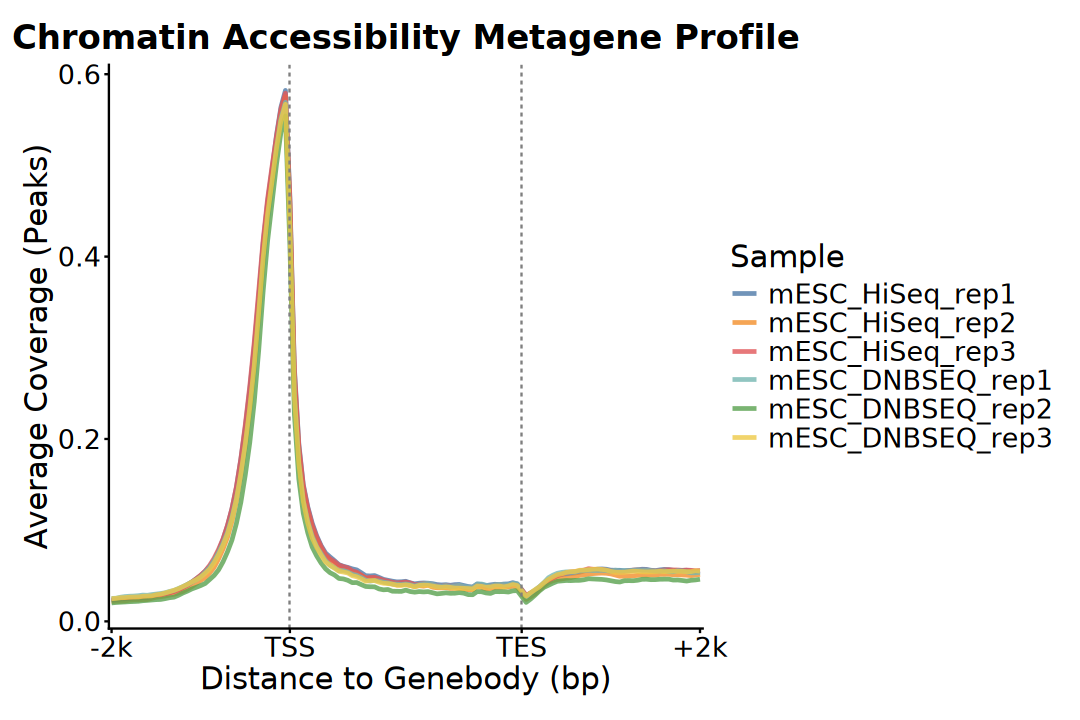

In [72]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Coverage)) +
    geom_line(
        aes(color = Sample, group = Sample), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) +
    # scale_color_brewer(palette = "Set1") +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Chromatin Accessibility Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Coverage (Peaks)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 6). Metagene Profile (Signals)

### a). deepTools

In [73]:
matrix_files <- file.path(data_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [74]:
compute_matrix_mean <- function(file, sample) {
    read.table(file, header = FALSE, sep = "\t", skip = 3) |>
        as.matrix() |> colMeans(na.rm = TRUE)
}

In [75]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [76]:
profiles_tss <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 2000, length.out = 400)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    separate(
        Sample, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell, levels = c("mESC", "mEF")), 
        Platform = factor(Platform, levels = c("HiSeq", "DNBSEQ")),
        Replicate = factor(Replicate))

head(profiles_tss)

Position,Sample,Cell,Platform,Replicate,Signal
<dbl>,<chr>,<fct>,<fct>,<fct>,<dbl>
-2000,mEF_DNBSEQ_rep1,mEF,DNBSEQ,rep1,13.57284
-2000,mEF_DNBSEQ_rep2,mEF,DNBSEQ,rep2,13.17121
-2000,mEF_DNBSEQ_rep3,mEF,DNBSEQ,rep3,13.64907
-2000,mEF_HiSeq_rep1,mEF,HiSeq,rep1,15.36117
-2000,mEF_HiSeq_rep2,mEF,HiSeq,rep2,16.66191
-2000,mEF_HiSeq_rep3,mEF,HiSeq,rep3,17.47982


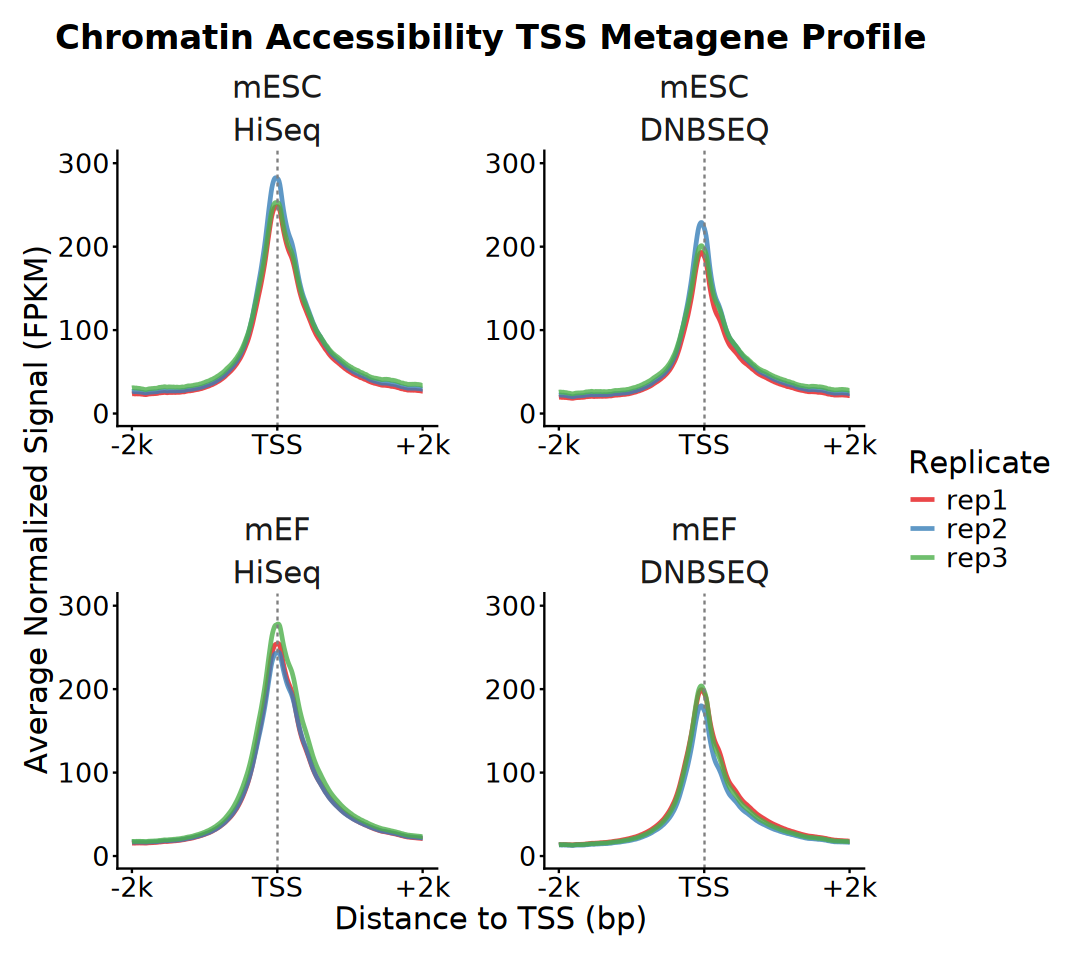

In [77]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(profiles_tss, aes(Position, Signal)) +
    geom_line(
        aes(color = Replicate), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) +
    scale_y_continuous(limits = c(0, 300)) + 
    scale_color_brewer(palette = "Set1") + 
    facet_wrap(Cell ~ Platform, scales = "free", strip.position = "top") +
    labs(
        title = "Chromatin Accessibility TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized Signal (FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.box.margin = margin(l = 10),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

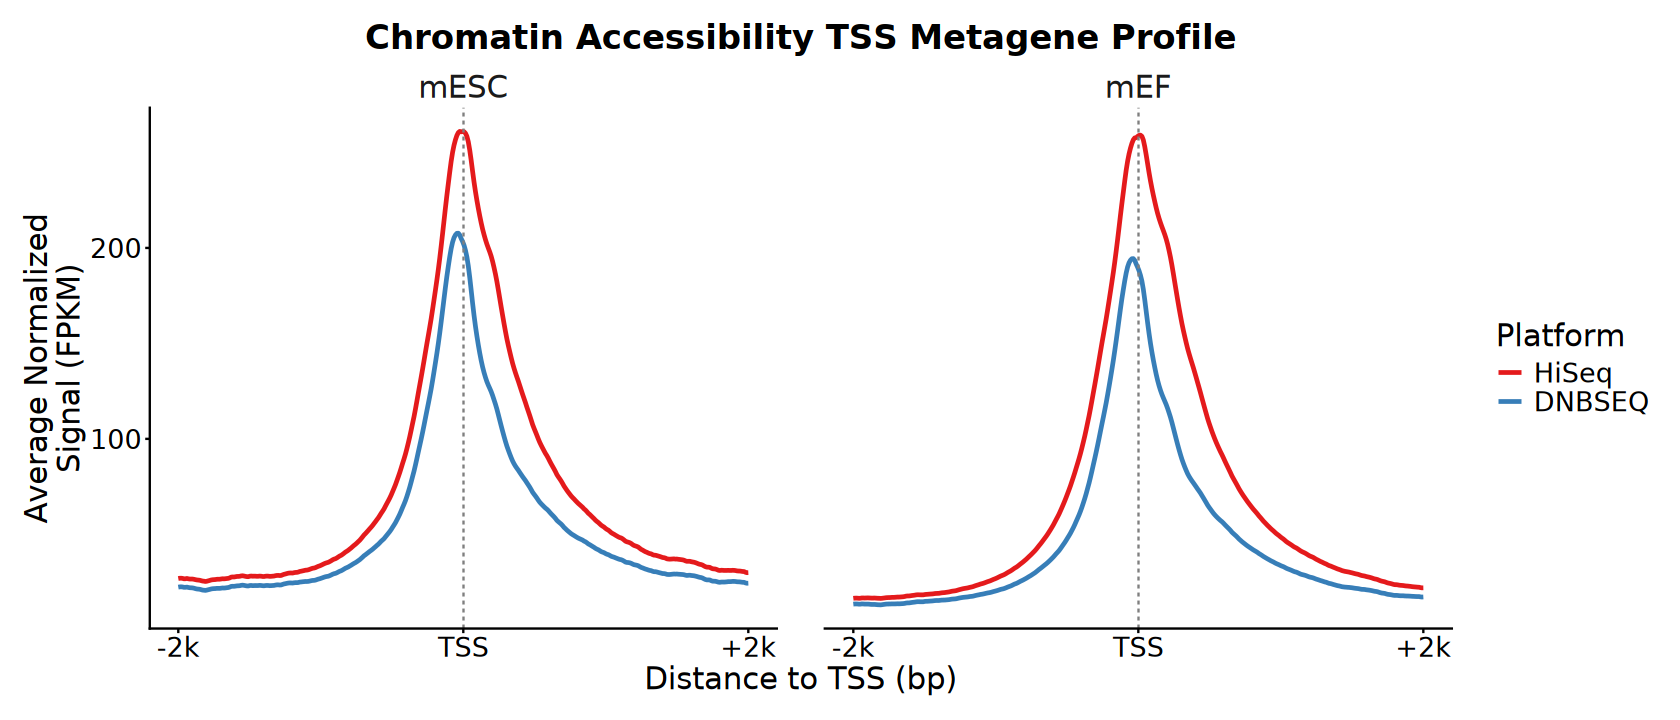

In [78]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(profiles_tss, aes(Position, Signal)) +
    stat_summary(
        aes(group = Platform, color = Platform), 
        fun = mean, geom = "line", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_color_brewer(palette = "Set1") + 
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) + 
    facet_wrap( ~ Cell, strip.position = "top") +
    labs(
        title = "Chromatin Accessibility TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized\nSignal (FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.box.margin = margin(l = 10),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). EnrichedHeatmap

In [79]:
# ~ 10 minutes
signals_gene_mat_list <- lapply(
    signals_list[1:6], normalizeToMatrix, GENES, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0, target_ratio = 0.4)

In [80]:
mean_mat <- Reduce("+", signals_gene_mat_list) / length(signals_gene_mat_list)
attributes(mean_mat) <- attributes(signals_gene_mat_list[[1]])

unified_row_order <- order(rowSums(mean_mat), decreasing = TRUE)

In [81]:
all_signals <- unlist(signals_gene_mat_list)
global_max_val <- quantile(abs(all_signals), 0.95, na.rm = TRUE)

unified_col_fun <- colorRamp2(
    c(0, global_max_val / 2, global_max_val), 
    # c("#ffffff", "#0077b6", "#03045e")
    c("#F5F5F5", "#F26419", "#7A0412")
)

In [82]:
ht_list <- NULL

for (i in seq_len(length(signals_gene_mat_list))) {
    mark_name <- names(signals_gene_mat_list)[i]
    ht_list <- ht_list + EnrichedHeatmap(
        signals_gene_mat_list[[i]], 
        name = mark_name,
        column_title = mark_name, 
        col = unified_col_fun,
        cluster_rows = FALSE,
        row_order = unified_row_order,
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = "#03045e"),
                ylim = c(0, 250), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        show_heatmap_legend = (i == 1),
        heatmap_legend_param = list(
            title = "FPKM",
            direction = "horizontal",
            title_position = "topcenter",
            legend_width = unit(4, "cm")),
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)
}

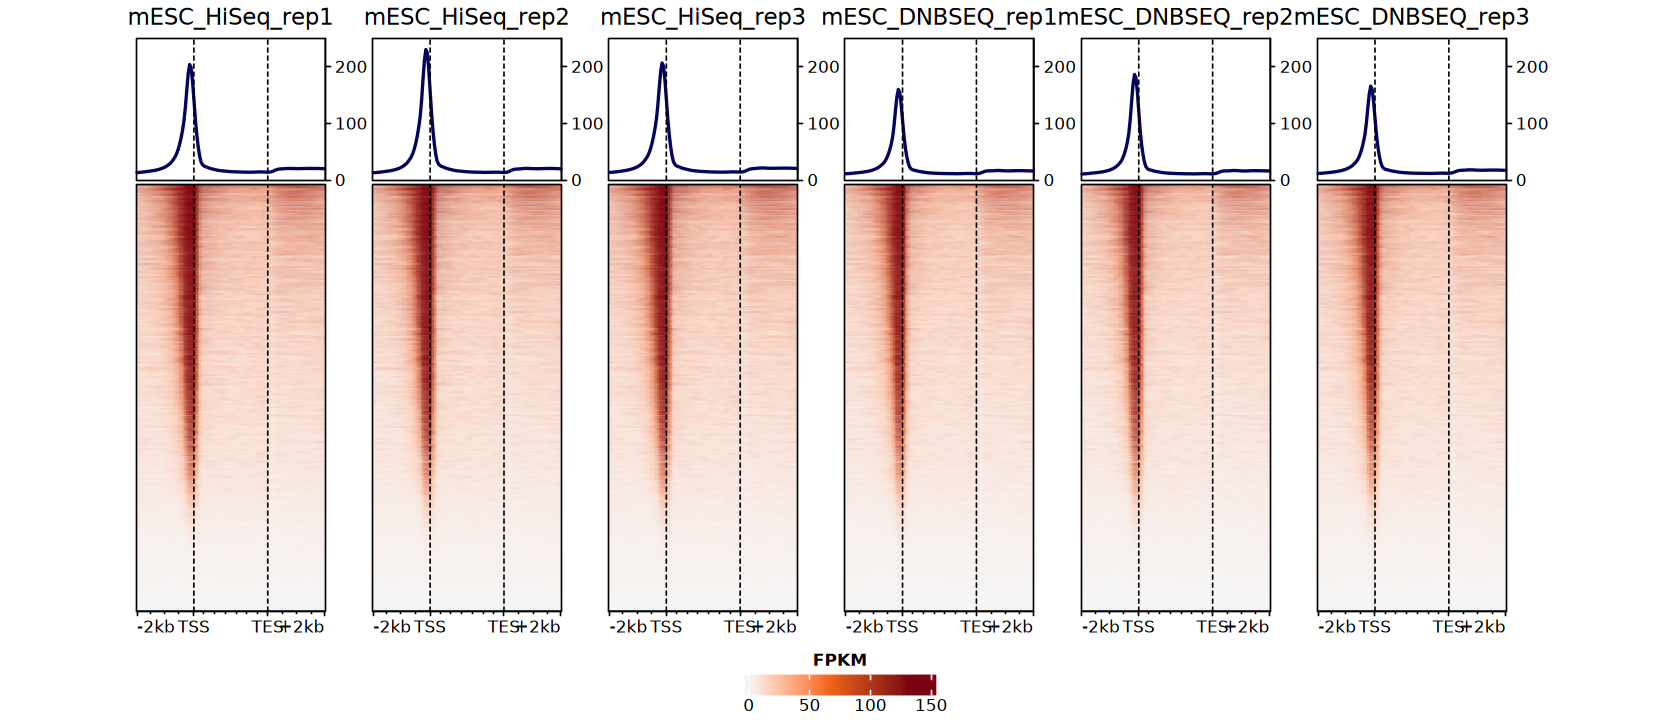

In [83]:
options(repr.plot.width = 14, repr.plot.height = 6)

draw(
    ht_list, 
    heatmap_legend_side = "bottom",
    ht_gap = unit(rep(10, length(signals_gene_mat_list)), "mm"))

In [84]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

profiles_df <- purrr::imap_dfr(
    signals_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Signal = colMeans(.x, na.rm = TRUE))) |>
    mutate(Sample = forcats::fct_inorder(as.character(Sample)))

head(profiles_df)

Position,Sample,Signal
<fct>,<fct>,<dbl>
u1,mESC_HiSeq_rep1,13.34323
u2,mESC_HiSeq_rep1,13.44366
u3,mESC_HiSeq_rep1,13.69468
u4,mESC_HiSeq_rep1,13.95793
u5,mESC_HiSeq_rep1,14.23086
u6,mESC_HiSeq_rep1,14.52845


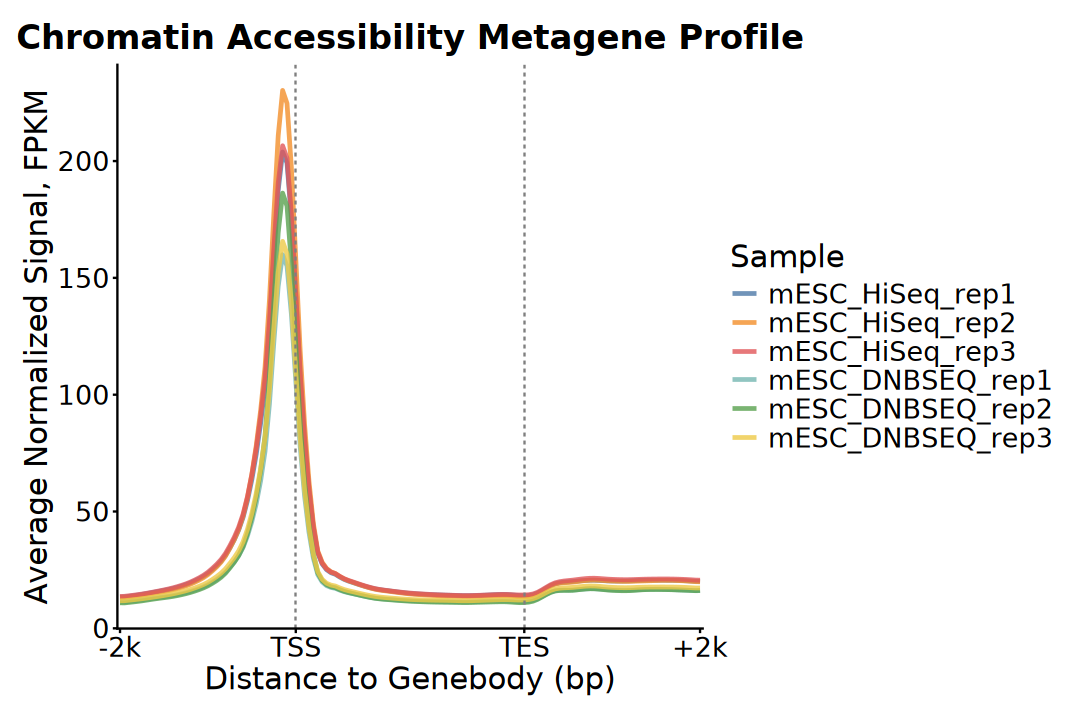

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Signal)) +
    geom_line(
        aes(color = Sample, group = Sample), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) +
    # scale_color_brewer(palette = "Set1") +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Chromatin Accessibility Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal, FPKM") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 7). IGV snapshot

In [86]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [87]:
genome = "mm10"
target_region <- "chr5:142889739-142922391"

In [88]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), 
        end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr5:142889739-142922391,chr5,142889739,142922391


In [89]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [90]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [91]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 14, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [92]:
colors_palette <- colorRampPalette(
    brewer.pal(8, "Set2"))(length(signals_list))
names(colors_palette) <- names(signals_list)

In [93]:
signal_tracks <- purrr::imap(
    signals_list, ~ Gviz::DataTrack(
        range = .x, name = .y, type = "histogram",
        chromosome = target_region$chr, genome = genome,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = colors_palette[.y],
        fill.histogram = colors_palette[.y]
    )
)

In [94]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 20, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

gene_info <- filter(gtf, type == "gene")

ranges(grtrack)$symbol <- gene_info$gene_name[
    match(ranges(grtrack)$gene, gene_info$gene_id)]

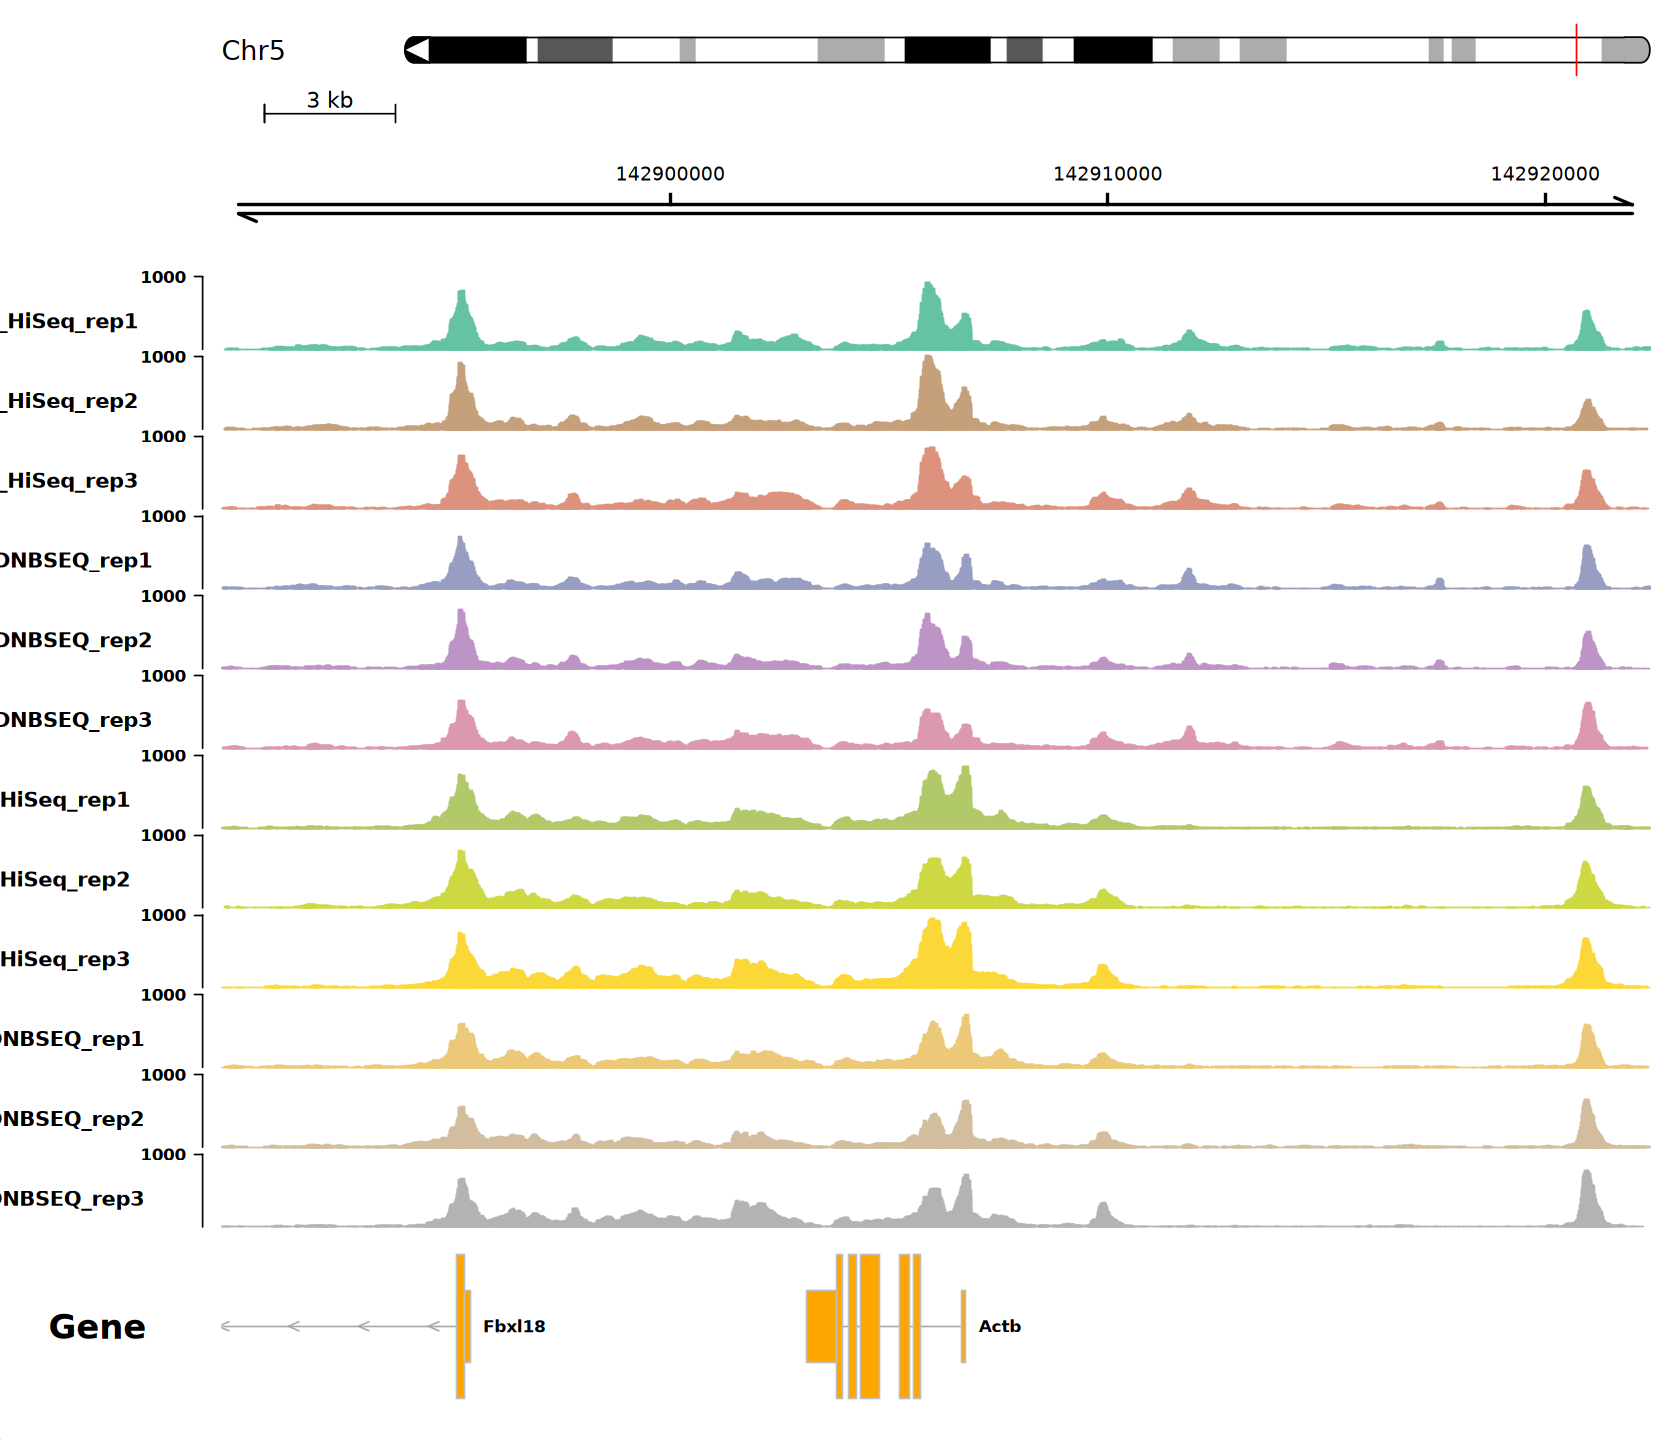

In [95]:
options(repr.plot.width = 14, repr.plot.height = 12)

plotTracks(
    trackList = c(plot_list, signal_tracks, grtrack), 
    chromosome = target_region$chr, 
    from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 6), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 1, 
    just.group = "right", extend.left = 0, 
    ylim = c(0, 1000), yTicksAt = c(1000))

# 5. Differential Accessibility Regions

> Notes:
> 1. Define the Analysis Region
> 2. Obtain the Counts Matrix
> 3. Normalization
> 4. Differential Analysis

In [96]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## a). Manual

> 1. Define the Analysis Region
>     - Peak-based methods
>         - Specific regions of the genome (Promoter, Enhancer, Gene body)
>         - Identify consensus peaks
>     - Window-based approaches
> 2. Obtain the **Raw Counts** Matrix
>     - deeptools, multiBamSummary (PE: fargment, `--samFlagInclude 64`)
>     - bedtools, multicov (?PE: reads)
> 3. Library Size (Normalization)
>     - Total number of mapped reads (default)
>     - Sum of mapped reads in the peaks
> 4. Differential Analysis
>     - DESeq2 (default)
>     - edgeR

In [97]:
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

In [98]:
raw_counts <- file.path(data_dir, "09_count", "HiSeq_consensus.counts.tsv") |>
    read_tsv(comment = "", show_col_types = FALSE) |>
    rename_with(~ stringr::str_remove_all(.x, "^#|'")) |>
    unite("pos", chr, start, end, sep = "_") |>
    column_to_rownames("pos") |>
    as.matrix()

head(raw_counts)

,mESC_HiSeq_rep1,mESC_HiSeq_rep2,mESC_HiSeq_rep3,mEF_HiSeq_rep1,mEF_HiSeq_rep2,mEF_HiSeq_rep3
chrX_6172616_6173117,27,24,28,31,45,36
chr8_34807068_34807569,350,346,297,477,393,460
chr8_34808863_34809364,103,105,105,137,156,180
chr8_34814478_34814979,135,127,129,45,82,101
chr8_34815047_34815548,40,51,42,68,89,115
chr8_34816120_34816621,118,125,119,180,145,142


In [99]:
coldata <- data.frame(sample = colnames(raw_counts)) |>
    separate(
        sample, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(Cell, levels = c("mESC", "mEF")), 
        Platform = factor(Platform, levels = c("HiSeq", "DNBSEQ")),
        Replicate = factor(Replicate)) |>
    arrange(Cell, Platform, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Platform,Replicate
,<fct>,<fct>,<fct>
mESC_HiSeq_rep1,mESC,HiSeq,rep1
mESC_HiSeq_rep2,mESC,HiSeq,rep2
mESC_HiSeq_rep3,mESC,HiSeq,rep3
mEF_HiSeq_rep1,mEF,HiSeq,rep1
mEF_HiSeq_rep2,mEF,HiSeq,rep2
mEF_HiSeq_rep3,mEF,HiSeq,rep3


In [100]:
dds <- DESeqDataSetFromMatrix(
    count = raw_counts, colData = coldata, design = ~ Cell)
dds

converting counts to integer mode



class: DESeqDataSet 
dim: 133418 6 
metadata(1): version
assays(1): counts
rownames(133418): chrX_6172616_6173117 chr8_34807068_34807569 ...
  chr9_18278670_18279171 chr9_18291971_18292472
rowData names(0):
colnames(6): mESC_HiSeq_rep1 mESC_HiSeq_rep2 ... mEF_HiSeq_rep2
  mEF_HiSeq_rep3
colData names(3): Cell Platform Replicate

In [101]:
dds <- estimateSizeFactors(dds)

In [102]:
sf <- sizeFactors(dds)
paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

mESC_HiSeq_rep1: 1.0072
mESC_HiSeq_rep2: 0.8788
mESC_HiSeq_rep3: 0.9282
mEF_HiSeq_rep1: 1.0959
mEF_HiSeq_rep2: 1.0572
mEF_HiSeq_rep3: 1.0834


In [103]:
# Library sizes were estimated using the total number of uniquely mapped reads.

library_sizes <- file.path(data_dir, "09_count", "bins_10kb.reads.tsv") |> 
    read.table(header = TRUE, row.names = 1)
library_sizes <- library_sizes[colnames(dds), ]

# Geometric mean
sf <- library_sizes / exp(mean(log(library_sizes)))
names(sf) <- colnames(dds)

paste(names(sf), round(sf, 4), sep = ": ") |> cat(sep = "\n")

mESC_HiSeq_rep1: 0.9229
mESC_HiSeq_rep2: 0.8066
mESC_HiSeq_rep3: 0.8734
mEF_HiSeq_rep1: 1.1725
mEF_HiSeq_rep2: 1.1591
mEF_HiSeq_rep3: 1.1318


In [104]:
sizeFactors(dds) <- sf

In [105]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [106]:
resultsNames(dds)

[1] "Intercept"        "Cell_mEF_vs_mESC"

In [107]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Cell_mEF_vs_mESC", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Cell", "mEF", "mESC"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 133418 with nonzero total read count
adjusted p-value < 0.05
LFC > 2.00 (up)    : 22308, 17%
LFC < -2.00 (down) : 22361, 17%
outliers [1]       : 1, 0.00075%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



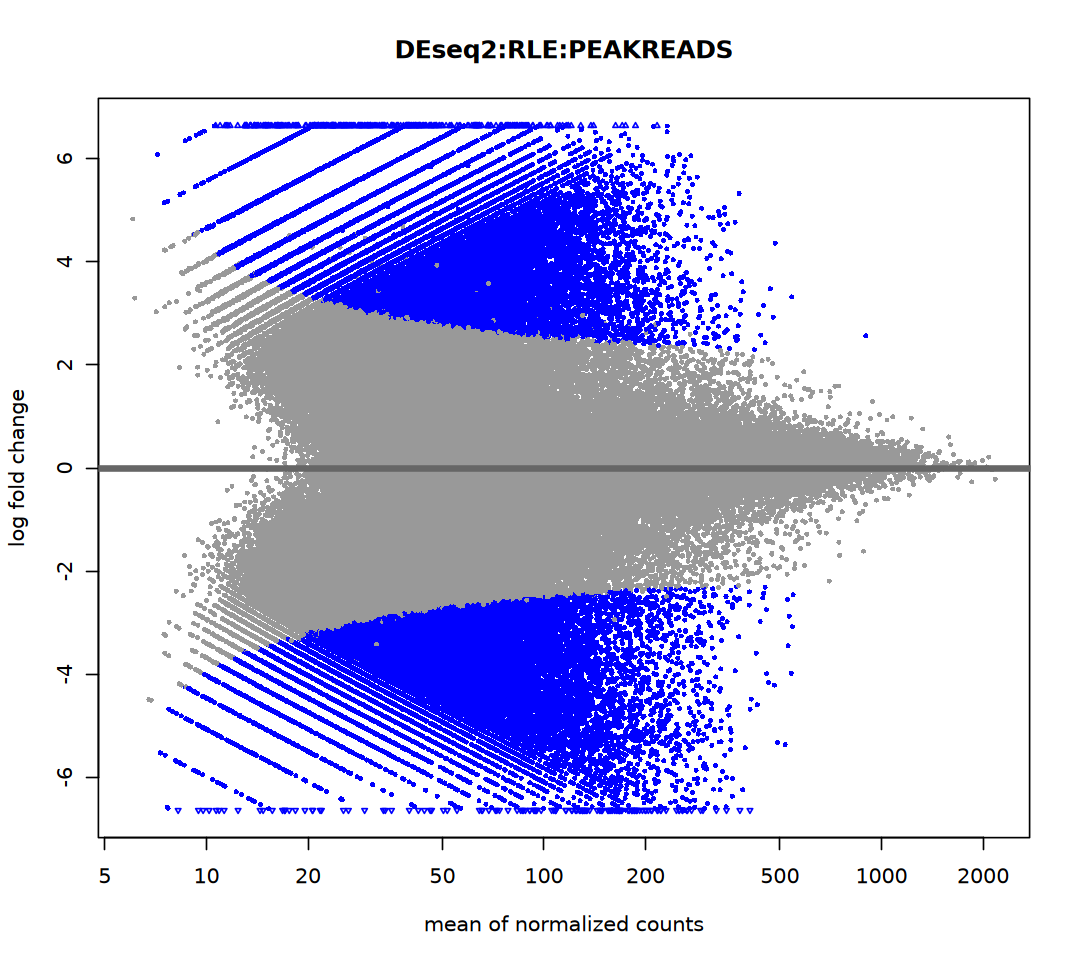

In [108]:
options(repr.plot.width = 9, repr.plot.height = 8)

plotMA(res, main = "DEseq2:RLE:PEAKREADS", alpha = p_cutoff)

In [109]:
deseq2_result <- res |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS"))) |>
    rownames_to_column(var = "peak_id") |>
    separate(
        peak_id, into = c("chr", "start", "end"), 
        sep = "_", remove = TRUE) |>
    GRanges()

deseq2_result

GRanges object with 133418 ranges and 7 metadata columns:
           seqnames              ranges strand |  baseMean       logFC
              <Rle>           <IRanges>  <Rle> | <numeric>   <numeric>
       [1]     chrX     6172616-6173117      * |   31.3569  0.09185886
       [2]     chr8   34807068-34807569      * |  383.4311  0.00622833
       [3]     chr8   34808863-34809364      * |  128.7466  0.18226583
       [4]     chr8   34814478-34814979      * |  108.3004 -1.18772611
       [5]     chr8   34815047-34815548      * |   65.1749  0.61558208
       ...      ...                 ...    ... .       ...         ...
  [133414]    chr11   21996882-21997383      * |  172.1362   -1.857533
  [133415]     chr2 102301445-102301946      * |   25.0584   -2.091783
  [133416]     chr9   18277409-18277910      * |   16.2698    1.987491
  [133417]     chr9   18278670-18279171      * |   29.8924   -1.129199
  [133418]     chr9   18291971-18292472      * |  414.0684    0.481299
               lfcS

In [110]:
res_tab <- table(deseq2_result$result)

message(
    "Differential accessibility peaks summary (DEseq2):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential accessibility peaks summary (DEseq2):
---------------------------------------------------
Gain (higher accessibility) : 22308
Loss (lower accessibility)  : 22361
Not significant             : 88749
---------------------------------------------------



In [111]:
dar_peaks <- list(
    Gain = deseq2_result[deseq2_result$result == "Gain", ], 
    Loss = deseq2_result[deseq2_result$result == "Loss", ])

In [112]:
dar_peaks <- lapply(
    dar_peaks, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c(
        "Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


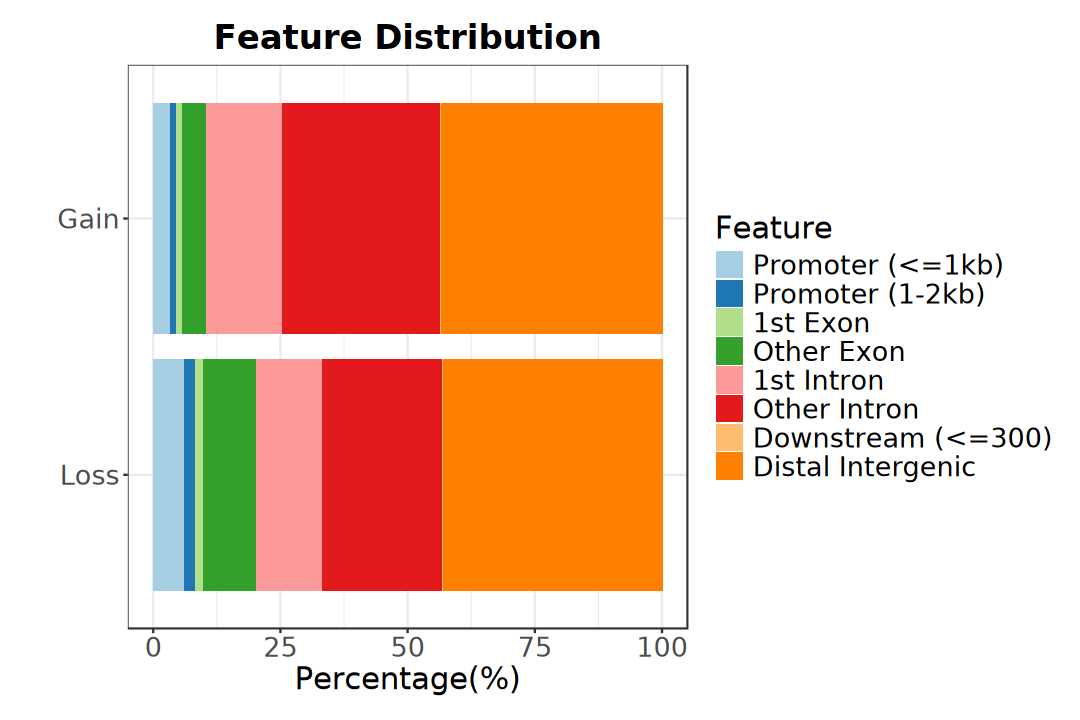

In [113]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(dar_peaks) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## b). DiffBind

> Differential analysis
> 1. DESeq2
> 2. edgeR

In [114]:
suppressPackageStartupMessages(library(DiffBind))
suppressPackageStartupMessages(library(BiocParallel))

In [115]:
bam_files <- file.path(data_dir, "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [116]:
sample_sheet <- data.frame(SampleID = names(bam_files)) |>
    separate(
        SampleID, into = c("Cell", "Platform", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Tissue = Cell, Factor = "ATAC", 
        Condition = Cell, Treatment = Platform, 
        Replicate = as.numeric(sub("rep", "", Replicate)), 
        bamReads = bam_files, Peaks = peaks_files,
        PeakCaller = "narrow") |>
    filter(Platform == "HiSeq") |>
    select(
        SampleID, Tissue, Factor, Condition, Treatment, Replicate, 
        bamReads, Peaks, PeakCaller)

sample_sheet |> dplyr::select(-any_of(c("Peaks", "bamReads")))

SampleID,Tissue,Factor,Condition,Treatment,Replicate,PeakCaller
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
mEF_HiSeq_rep1,mEF,ATAC,mEF,HiSeq,1,narrow
mEF_HiSeq_rep2,mEF,ATAC,mEF,HiSeq,2,narrow
mEF_HiSeq_rep3,mEF,ATAC,mEF,HiSeq,3,narrow
mESC_HiSeq_rep1,mESC,ATAC,mESC,HiSeq,1,narrow
mESC_HiSeq_rep2,mESC,ATAC,mESC,HiSeq,2,narrow
mESC_HiSeq_rep3,mESC,ATAC,mESC,HiSeq,3,narrow


In [117]:
write.csv(
    sample_sheet, file.path(data_dir, "01_stats", "diffbind_sample.csv"), 
    quote = FALSE, row.names = FALSE)

In [118]:
dbObj <- dba(sampleSheet = file.path(
    data_dir, "01_stats", "diffbind_sample.csv"))
dbObj

mEF_HiSeq_rep1 mEF ATAC mEF HiSeq 1 narrow



mEF_HiSeq_rep2 mEF ATAC mEF HiSeq 2 narrow

mEF_HiSeq_rep3 mEF ATAC mEF HiSeq 3 narrow

mESC_HiSeq_rep1 mESC ATAC mESC HiSeq 1 narrow

mESC_HiSeq_rep2 mESC ATAC mESC HiSeq 2 narrow

mESC_HiSeq_rep3 mESC ATAC mESC HiSeq 3 narrow



6 Samples, 143794 sites in matrix (189407 total):
               ID Tissue Factor Condition Treatment Replicate Intervals
1  mEF_HiSeq_rep1    mEF   ATAC       mEF     HiSeq         1     95762
2  mEF_HiSeq_rep2    mEF   ATAC       mEF     HiSeq         2     92753
3  mEF_HiSeq_rep3    mEF   ATAC       mEF     HiSeq         3     92420
4 mESC_HiSeq_rep1   mESC   ATAC      mESC     HiSeq         1     99318
5 mESC_HiSeq_rep2   mESC   ATAC      mESC     HiSeq         2     96772
6 mESC_HiSeq_rep3   mESC   ATAC      mESC     HiSeq         3     98872

In [119]:
dbObj <- dba.blacklist(dbObj, blacklist = DBA_BLACKLIST_MM10, greylist = FALSE)

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...



Removed: 10597 of 575897 intervals.

Removed: 3285 merged (of 189407) and 2579 (of 143794) consensus.



In [120]:
# Force registration of a multi-core environment with only 4 workers (cores).
# register(MulticoreParam(workers = 4))

# Set the number of CPU cores for parallel processing to 6
print(dbObj$config$cores)
dbObj$config$cores <- 4
# Check (or return) the current status of parallel execution (TRUE/FALSE)
print(dbObj$config$RunParallel)

[1] TRUE

[1] 1

In [121]:
# Count reads in binding site intervals
# (16 cores: ~20 min, memory consumption, 64G)
# (6 cores: ~20 min, memory consumption, 32G?)
# (1 cores: ~60 min, memory consumption, 16G)
dbObj <- dba.count(dbObj, bUseSummarizeOverlaps = TRUE, bParallel = TRUE)

saveRDS(dbObj, file.path(data_dir, "01_stats", "diffbind_dbObj.rds"))
# dbObj <- readRDS(file.path(data_dir, "01_stats", "diffbind_dbObj.rds"))

dbObj

Computing summits...

Re-centering peaks...



6 Samples, 141209 sites in matrix:
               ID Tissue Factor Condition Treatment Replicate    Reads FRiP
1  mEF_HiSeq_rep1    mEF   ATAC       mEF     HiSeq         1 35447814 0.35
2  mEF_HiSeq_rep2    mEF   ATAC       mEF     HiSeq         2 35035676 0.35
3  mEF_HiSeq_rep3    mEF   ATAC       mEF     HiSeq         3 34178350 0.38
4 mESC_HiSeq_rep1   mESC   ATAC      mESC     HiSeq         1 27898677 0.36
5 mESC_HiSeq_rep2   mESC   ATAC      mESC     HiSeq         2 24384395 0.38
6 mESC_HiSeq_rep3   mESC   ATAC      mESC     HiSeq         3 26395358 0.36

In [122]:
# Normalization
dbObj <- dba.normalize(
    dbObj, normalize = DBA_NORM_TMM, 
    library = DBA_LIBSIZE_PEAKREADS, 
    background = FALSE)

In [123]:
# Sets up contrasts for differential binding affinity analysis
dbObj <- dba.contrast(
    dbObj, categories = DBA_TISSUE, minMembers = 3, 
    reorderMeta = list(Condition = "mESC"))

dbObj

Computing results names...



6 Samples, 141209 sites in matrix:
               ID Tissue Factor Condition Treatment Replicate    Reads FRiP
1  mEF_HiSeq_rep1    mEF   ATAC       mEF     HiSeq         1 35447814 0.35
2  mEF_HiSeq_rep2    mEF   ATAC       mEF     HiSeq         2 35035676 0.35
3  mEF_HiSeq_rep3    mEF   ATAC       mEF     HiSeq         3 34178350 0.38
4 mESC_HiSeq_rep1   mESC   ATAC      mESC     HiSeq         1 27898677 0.36
5 mESC_HiSeq_rep2   mESC   ATAC      mESC     HiSeq         2 24384395 0.38
6 mESC_HiSeq_rep3   mESC   ATAC      mESC     HiSeq         3 26395358 0.36

Design: [~Tissue] | 1 Contrast:
  Factor Group Samples Group2 Samples2
1 Tissue   mEF       3   mESC        3

In [124]:
# Perform differential binding affinity analysis
dbObj <- dba.analyze(dbObj, method = DBA_DESEQ2)
dba.show(dbObj, bContrasts = TRUE)

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Tissue,mEF,3,mESC,3,122441


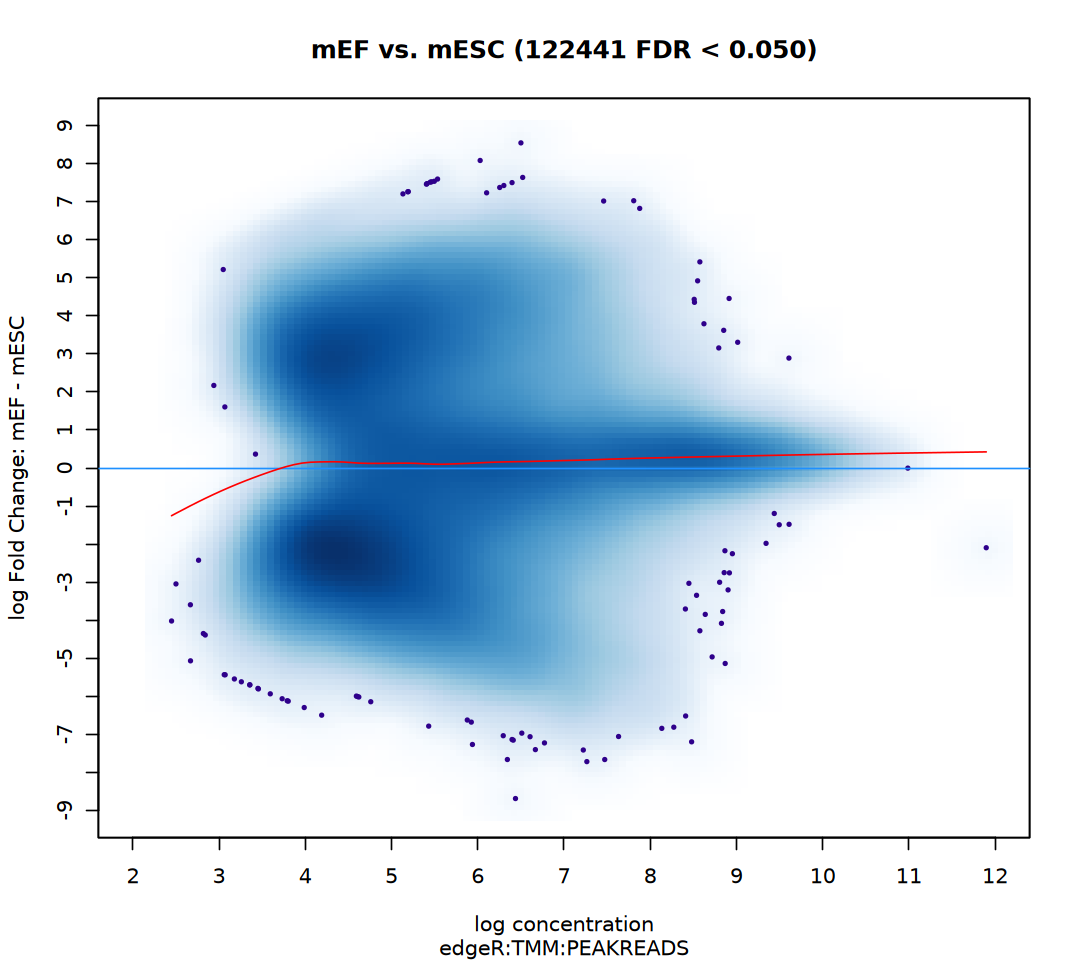

In [125]:
options(repr.plot.width = 9, repr.plot.height = 8)

dba.plotMA(dbObj, sub = "edgeR:TMM:PEAKREADS", bSignificant = FALSE)

In [126]:
# Generate a report for a differential binding affinity analysis

diffbind_result <- dba.report(
    dbObj, method = DBA_DESEQ2, contrast = 1, 
    fold = 0, th = 1, bUsePval = FALSE)

diffbind_result$result = case_when(
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold >  logfc_cutoff ~ "Gain",
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold < -logfc_cutoff ~ "Loss",
    TRUE ~ "NS") |> 
    factor(levels = c("Gain", "Loss", "NS"))

diffbind_result

GRanges object with 141209 ranges and 7 metadata columns:
         seqnames              ranges strand |      Conc  Conc_mEF Conc_mESC
            <Rle>           <IRanges>  <Rle> | <numeric> <numeric> <numeric>
  102819     chr5 109553304-109553704      * |   8.82608   5.64618   9.74420
   37260    chr13   74399332-74399732      * |   8.86936   4.66373   9.82973
  128069     chr8   94186515-94186915      * |   8.90295   6.54245   9.75517
   32311    chr12 109417596-109417996      * |   8.91491   9.85128   5.38041
   96630     chr4 141570030-141570430      * |   8.84020   5.95414   9.73916
     ...      ...                 ...    ... .       ...       ...       ...
   44936    chr14 121073425-121073825      * |   4.71455   4.71634   4.71276
   11082    chr10   20181179-20181579      * |   5.21818   5.21737   5.21898
  116047     chr7   27332528-27332928      * |   7.80350   7.80362   7.80337
  141157     chrY     1010172-1010572      * |   3.96966   4.63704   2.68973
  141158     chrY 

In [127]:
res_tab <- table(diffbind_result$result)

message(
    "Differential accessibility peaks summary (DiffBind):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential accessibility peaks summary (DiffBind):
---------------------------------------------------
Gain (higher accessibility) : 39498
Loss (lower accessibility)  : 35224
Not significant             : 66487
---------------------------------------------------



## c). csaw
 
> Differential analysis
> 1. edgeR

In [128]:
suppressPackageStartupMessages(library(csaw))
suppressPackageStartupMessages(library(rtracklayer))

In [129]:
bam_files <- file.path(data_dir, "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    (\(x) x[grepl("HiSeq", x)])() |>
    set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

paste(names(bam_files), basename(bam_files), sep = ": ") |> cat(sep = "\n")

mEF_HiSeq_rep1: mEF_HiSeq_rep1.bam
mEF_HiSeq_rep2: mEF_HiSeq_rep2.bam
mEF_HiSeq_rep3: mEF_HiSeq_rep3.bam
mESC_HiSeq_rep1: mESC_HiSeq_rep1.bam
mESC_HiSeq_rep2: mESC_HiSeq_rep2.bam
mESC_HiSeq_rep3: mESC_HiSeq_rep3.bam


In [130]:
# Filtering out low-quality reads
param <- readParam(
    pe = "both", max.frag = 1000, dedup = FALSE, minq = NA, 
    restrict = standard_chromosome, discard = blacklist)

param

    Extracting reads in paired-end mode
        Maximum allowed distance between paired reads is 1000 bp
    Duplicate removal is turned off 
    No minimum threshold is set on the mapping score
    Reads are extracted from both strands
    Read extraction is limited to 21 sequences
    Reads in 3435 regions will be discarded

In [131]:
# Compute correlation coefficients between reads (~ 5 min)
corr_reads <- correlateReads(bam_files[1], max.dist = 1000, param = param)

# Estimate the average fragment length by maximizing the cross-correlations.
message("Average of fragment size: ", maximizeCcf(corr_reads))

Average of fragment size: 105



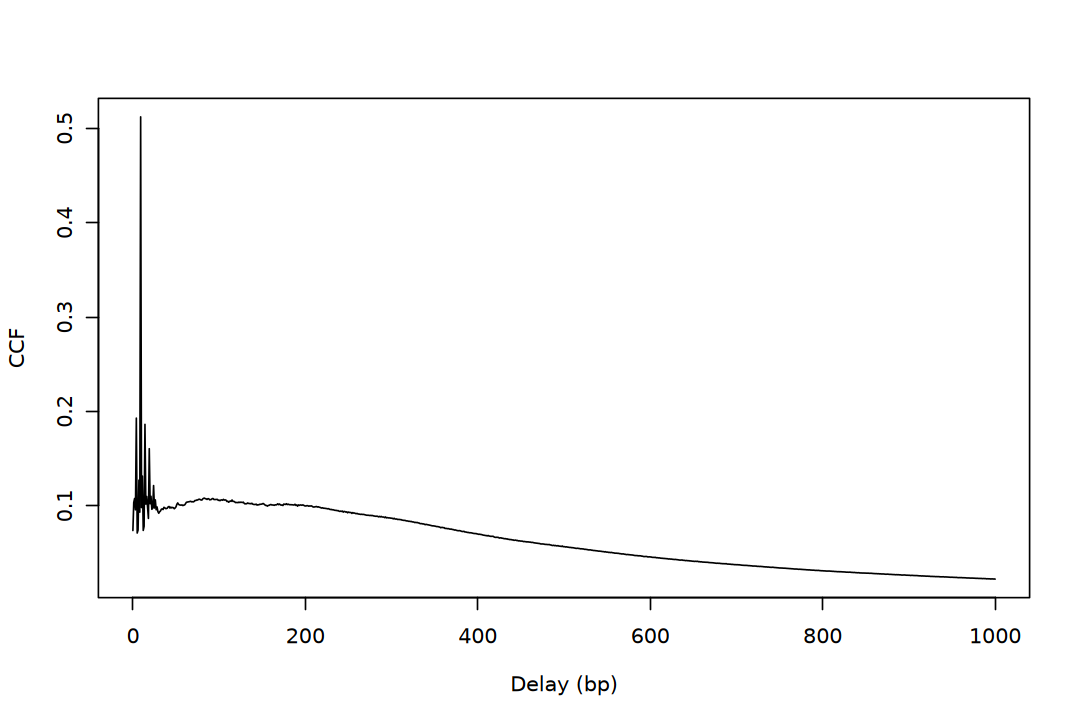

In [132]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(0:1000, corr_reads, type = "l", ylab = "CCF", xlab = "Delay (bp)")

In [133]:
# Estimating the fragment length of paired-end sequence (~ 3 min)
fragment_length <- getPESizes(bam_files[1], param = param)

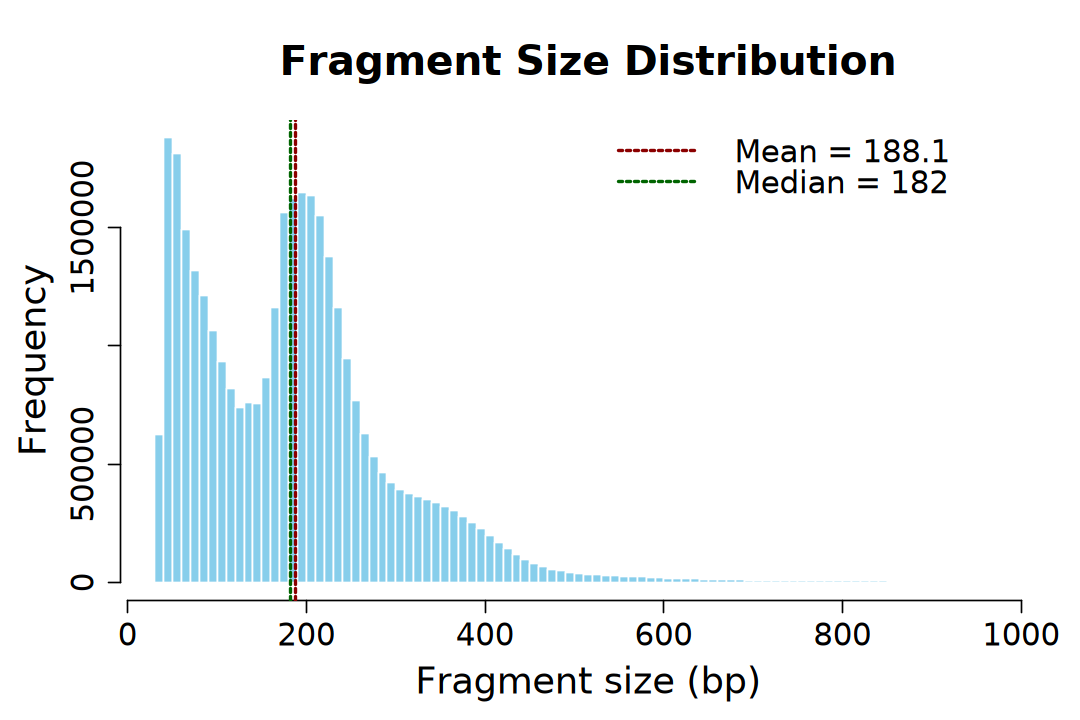

In [134]:
options(repr.plot.width = 9, repr.plot.height = 6)

par(mar = c(5, 5, 5, 1))

hist(fragment_length$sizes, breaks = 100, probability = FALSE,
    col = "skyblue", border = "white",
    main = "Fragment Size Distribution",
    xlab = "Fragment size (bp)", ylab = "Frequency",
    cex.main = 2, cex.lab = 1.8, cex.axis = 1.5)

m_mean <- mean(fragment_length$sizes, na.rm = TRUE)
abline(v = m_mean, col = "darkred", lwd = 2, lty = 2)

m_median <- median(fragment_length$sizes, na.rm = TRUE)
abline(v = m_median, col = "darkgreen", lwd = 2, lty = 2)

legend("topright", legend = c(
    paste0("Mean = ", round(m_mean, 2)), 
    paste0("Median = ", round(m_median, 2))), 
    col = c("darkred", "darkgreen"), 
    lty = 2, lwd = 2, bty = "n", cex = 1.5)

In [135]:
# Count reads overlapping each window (~ 10 min)
# improve efficiency: spacing = (width + ext) / 2
wins_counts <- windowCounts(
    bam_files, spacing = 50, width = 150, ext = 150, shift = 0,
    filter = 10, bin = FALSE, param = param)

wins_counts

# region_counts <- regionCounts(
#     bam_files, regions = target_region, ext = 150,
#     filter = 10, param = param)

class: RangedSummarizedExperiment 
dim: 23318916 6 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames: NULL
colData names(4): bam.files totals ext rlen

In [136]:
# Filtering windows by abundance (~ 10 min)
bins_counts <- windowCounts(
    bam_files, bin = TRUE, width = 10000, param = param)

bins_counts

class: RangedSummarizedExperiment 
dim: 248696 6 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames: NULL
colData names(4): bam.files totals ext rlen

In [137]:
# Global filter on the background enrichment
filter.stat <- filterWindowsGlobal(wins_counts, bins_counts)
keep <- filter.stat$filter > log2(3)

summary(keep)

    Mode    FALSE     TRUE 
 logical 19975372  3343544 

In [138]:
wins_counts_filter <- wins_counts[keep, ]

wins_counts_filter

class: RangedSummarizedExperiment 
dim: 3343544 6 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames: NULL
colData names(4): bam.files totals ext rlen

In [139]:
# Normalizing for technical biases
# 1. Eliminating composition biases (edgeR' TMM)
# 2. Eliminating efficiency biases
wins_counts_filter <- normFactors(
    bins_counts, se.out = wins_counts_filter)

wins_counts_filter

class: RangedSummarizedExperiment 
dim: 3343544 6 
metadata(6): spacing width ... param final.ext
assays(1): counts
rownames: NULL
rowData names(0):
colnames: NULL
colData names(5): bam.files totals ext rlen norm.factors

In [140]:
dgel <- asDGEList(wins_counts_filter)
colnames(dgel) <- names(bam_files)
dgel$samples$group <- sub("_.*", "", colnames(dgel)) |> 
    factor(levels = c("mESC", "mEF"))

In [141]:
design <- model.matrix(~ group, data = dgel$samples)

In [142]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [143]:
wins_counts_merged <- mergeResults(
    wins_counts_filter, qlf$table, tol = 1000L, 
    merge.args = list(max.width = 5000))

In [144]:
csaw_result <- wins_counts_merged$combined |> 
    as.data.frame() |>
    dplyr::rename(padj = FDR, pvalue = PValue, logFC = rep.logFC) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Gain",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Loss",
            TRUE ~ "NS") |> 
            factor(levels = c("Gain", "Loss", "NS")))

head(csaw_result)

,num.tests,num.up.logFC,num.down.logFC,pvalue,padj,direction,rep.test,logFC,result
,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<dbl>,<fct>
1,10,0,10,6.216573e-11,2.425942e-10,down,7,-3.9184514,Loss
2,13,0,13,1.456024e-19,4.338701e-18,down,19,-6.8101329,Loss
3,11,11,0,1.109994e-08,2.797517e-08,up,33,4.0246973,Gain
4,8,0,8,9.822194e-11,3.684646e-10,down,37,-2.9587021,Loss
5,5,5,0,1.687331e-06,2.979382e-06,up,45,2.4317672,Gain
6,5,0,0,1.614638e-01,1.739637e-01,up,50,0.5603787,NS


In [145]:
res_tab <- table(csaw_result$result)

message(
    "Differential accessibility peaks summary (csaw):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential accessibility peaks summary (csaw):
---------------------------------------------------
Gain (higher accessibility) : 47236
Loss (lower accessibility)  : 65540
Not significant             : 68189
---------------------------------------------------



# Reference

> 1. [The csaw Book](https://bioconductor.org/books/release/csawBook/)